<p><font color="#0E7490"><b>KENNESAW STATE UNIVERSITY  |  iCARE LAB  |  FIRST-YEAR SCHOLARS 2026–2027</b></font></p>
<h1><font color="#174EA6"><b>Python Module 3</b></font></h1>
<h2><font color="#1D4ED8"><b>NumPy, Arrays, Images, and Simple Visualization</b></font></h2>
<p><font color="#334155">1D Arrays • Array Summaries • 2D Grids & Slicing • Binary Masks • Matplotlib Plots • Grayscale Images</font></p>
<p><font color="#334155">October 28, 2026  |  Google Colab  |  Designed for complete beginners</font></p>
<hr>
<p><font color="#1D4ED8"><b>BLUE</b></font> = lessons &nbsp;&nbsp; <font color="#0E7490"><b>TEAL</b></font> = explanations &nbsp;&nbsp; <font color="#7135B5"><b>PURPLE</b></font> = exercises &nbsp;&nbsp; <font color="#A34F00"><b>ORANGE</b></font> = hints &nbsp;&nbsp; <font color="#177345"><b>GREEN</b></font> = solutions</p>

<p><font color="#1D4ED8"><b>How to use this notebook</b></font></p>
<p><font color="#0E7490"><b>1.</b></font> Run each code cell with <b>Shift + Enter</b> (or ▶). &nbsp; <font color="#0E7490"><b>2.</b></font> Read the intuitive explanation and run the <b>two worked examples</b> in each lesson. &nbsp; <font color="#0E7490"><b>3.</b></font> Complete the <b>five exercises</b> in order. &nbsp; <font color="#0E7490"><b>4.</b></font> Check the <font color="#177345"><b>solutions at the very end</b></font> only after trying.</p>
<p><font color="#A34F00"><b>Before you begin:</b></font> Use the default <b>CPU</b> runtime in Google Colab. All medical imaging numbers and tiny pixel grids in this notebook are <b>fictional data</b> created for programming practice.</p>

<h3><font color="#0E7490"><b>A quick bridge from Module 2 to Medical Images</b></font></h3>
<p><font color="#334155">In Modules 1 and 2, you used Python <b>lists</b> (like <code>[20, 22, 25]</code>) and <code>for</code> loops to process numbers one by one. That works well for 5 numbers. However, a single 3D CT scan can contain over <b>10 million voxels</b> (3D pixels). Looping through millions of numbers one at a time in standard Python is too slow. Today you will learn <b>NumPy</b> (Numerical Python), which stores numbers in a high-speed grid called an <b>array</b>, and <b>Matplotlib</b>, which turns those grids of numbers into visual plots and grayscale images.</font></p>

<hr>
<h2><font color="#1D4ED8"><b>1. From Python Lists to NumPy Arrays (1D Arrays)</b></font></h2>

<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#0E7490">Think of a regular Python list as a row of separate cardboard boxes—to add 5 to every number, you have to open each box one by one with a <code>for</code> loop. A <b>NumPy array</b> puts all those numbers onto a single conveyor belt. When you multiply a NumPy array by 2, or add 5 to it, Python updates <b>every number at the exact same time</b> without a loop. This is called <b>vectorized math</b>.</font></p>

<p><font color="#334155"><b>How Python List vs. NumPy Array behaves:</b></font></p>
<ul>
  <li><font color="#334155"><b>Python List:</b> <code>[1, 2, 3] * 2</code> repeats the list → <code>[1, 2, 3, 1, 2, 3]</code></font></li>
  <li><font color="#0E7490"><b>NumPy Array:</b> <code>np.array([1, 2, 3]) * 2</code> multiplies the numbers → <code>[2, 4, 6]</code></font></li>
</ul>

<p><font color="#A34F00"><b>Remember:</b></font> <font color="#A34F00">Before using NumPy, we import it once using the nickname <code>np</code>: <code>import numpy as np</code>. To create an array from a list, write <code>np.array([10, 20, 30])</code>.</font></p>

<h3><font color="#0E7490"><b>Worked example 1: Create an array and convert units without a loop</b></font></h3>
<p><font color="#334155">Imagine we measured three aorta diameters in millimeters: <code>20.0</code>, <code>24.0</code>, and <code>30.0</code>. Let's store them in a NumPy array and divide by <code>10</code> to convert all of them to centimeters at once.</font></p>
<p><font color="#334155">Try it:</font> Run the next cell. <font color="#0E7490"><b>Expected output:</b></font> <code>Diameters (mm): [20. 24. 30.]</code> and <code>Diameters (cm): [2.  2.4 3. ]</code></p>

In [3]:
import numpy as np

diameters_mm = np.array([20.0, 24.0, 30.0])
diameters_cm = diameters_mm / 10

print("Diameters (mm):", diameters_mm)
print("Diameters (cm):", diameters_cm)

Diameters (mm): [20. 24. 30.]
Diameters (cm): [2.  2.4 3. ]


<p><font color="#A34F00"><b>What to notice in the output above:</b></font> <font color="#334155">When Python prints a <b>NumPy array</b> like <code>[20. 24. 30.]</code>, it leaves out the commas between numbers and writes <code>20.0</code> as <code>20.</code> to save space. That is how you can immediately tell you are looking at a NumPy array instead of a regular Python list!</font></p>

<h3><font color="#0E7490"><b>Worked example 2: Compare two arrays at the same time (Element-by-Element Math)</b></font></h3>
<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">What happens when you subtract or add <b>two NumPy arrays</b> of the same length? Picture two egg cartons lined up one above the other. Python automatically pairs up the matching positions (Index 0 with Index 0, Index 1 with Index 1, and Index 2 with Index 2) and calculates all of them at once.</font></p>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:8px;text-align:center;">
<tr style="background:#eaf3ff"><th style="padding:6px"><font color="#1D4ED8"><b>Position (Index)</b></font></th><th style="padding:6px"><font color="#1D4ED8"><b>Index 0 (Scan 1)</b></font></th><th style="padding:6px"><font color="#1D4ED8"><b>Index 1 (Scan 2)</b></font></th><th style="padding:6px"><font color="#1D4ED8"><b>Index 2 (Scan 3)</b></font></th></tr>
<tr><td style="padding:6px"><b>AI Prediction (mL)</b></td><td style="padding:6px">95</td><td style="padding:6px">160</td><td style="padding:6px">198</td></tr>
<tr><td style="padding:6px"><b>Reference Truth (mL)</b></td><td style="padding:6px">100</td><td style="padding:6px">150</td><td style="padding:6px">200</td></tr>
<tr style="background:#f0fdf4"><td style="padding:6px"><font color="#177345"><b>AI - Reference</b></font></td><td style="padding:6px"><font color="#177345">95 - 100 = <b>-5</b></font></td><td style="padding:6px"><font color="#177345">160 - 150 = <b>10</b></font></td><td style="padding:6px"><font color="#177345">198 - 200 = <b>-2</b></font></td></tr>
<tr style="background:#e0f2fe"><td style="padding:6px"><font color="#0E7490"><b>Absolute Error: np.abs()</b></font></td><td style="padding:6px"><font color="#0E7490"><b>5</b></font></td><td style="padding:6px"><font color="#0E7490"><b>10</b></font></td><td style="padding:6px"><font color="#0E7490"><b>2</b></font></td></tr>
</table>

<p><font color="#A34F00"><b>Remember:</b></font> <font color="#A34F00">Both arrays must have the <b>exact same number of items</b> to pair up. Use <code>np.abs()</code> to turn negative differences into positive error sizes across the whole array.</font></p>
<p><font color="#334155">Try it:</font> Run the next cell. <font color="#0E7490"><b>Expected output:</b></font> <code>Signed differences: [-5 10 -2]</code> and <code>Absolute errors: [ 5 10  2]</code></p>

In [4]:
ai_volumes = np.array([95, 160, 198])
reference_volumes = np.array([100, 150, 200])

differences = ai_volumes - reference_volumes
absolute_errors = np.abs(differences)

print("Signed differences:", differences)
print("Absolute errors:", absolute_errors)

Signed differences: [-5 10 -2]
Absolute errors: [ 5 10  2]


<h3><font color="#7135B5"><b>Your turn: 5 exercises</b></font></h3>
<p><font color="#7135B5">Start with Exercise 1.1 and work toward Exercise 1.5.</font> <font color="#334155">Because you already ran <code>import numpy as np</code> in Worked Example 1, NumPy is active in your notebook and ready to use. Use the exact starting numbers given in each problem so you can easily check your output against the expected result.</font></p>

<p><font color="#7135B5"><b>Exercise 1.1 — Create your first NumPy array</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Turn a regular list of three CT slice counts—<code>10</code>, <code>20</code>, and <code>30</code>—into a NumPy array named <code>slice_counts</code>, then print it.</font></p>
<p><font color="#0E7490"><b>Why this matters:</b></font> <font color="#334155">Before we can use fast array math on research measurements, we first have to wrap our Python list inside <code>np.array(...)</code>.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>[10 20 30]</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Write <code>slice_counts = np.array([10, 20, 30])</code> on the first line, and <code>print(slice_counts)</code> on the second line. Notice that the square brackets <code>[ ]</code> go inside the parentheses <code>( )</code>.</font></p>

In [5]:
# Exercise 1.1 — Create your first NumPy array
# Write your Python code below.

<p><font color="#7135B5"><b>Exercise 1.2 — Multiply every number at once (Voxel Volumes)</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Create a NumPy array named <code>voxel_counts</code> with the values <code>100</code>, <code>250</code>, and <code>400</code>. If each voxel has a volume of <code>2</code> cubic millimeters (mm³), multiply the entire array by <code>2</code> and print the result.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">In a medical scan, different organs contain different numbers of 3D pixels (voxels). Instead of writing a <code>for</code> loop to calculate the volume of each organ one by one, multiplying a NumPy array by <code>2</code> scales every single organ's count at the exact same moment.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>[200 500 800]</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Create the array: <code>voxel_counts = np.array([100, 250, 400])</code>. &nbsp; 2. Multiply and print: <code>print(voxel_counts * 2)</code> (or save it in a variable like <code>volumes = voxel_counts * 2</code> and print <code>volumes</code>).</font></p>

In [6]:
# Exercise 1.2 — Multiply every number at once (Voxel Volumes)
# Write your Python code below.

<p><font color="#7135B5"><b>Exercise 1.3 — Convert cubic millimeters to milliliters</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Store three structure volumes in cubic millimeters—<code>1500</code>, <code>2500</code>, and <code>4000</code>—in a NumPy array named <code>volumes_mm3</code>. Convert all three values into milliliters (mL) by dividing the array by <code>1000</code>, and print the result.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">In 3D medical imaging, software often counts tiny voxels in cubic millimeters (mm³), which produces huge numbers. Doctors and researchers prefer milliliters (mL) because <code>1,000 mm³ = 1 mL</code>. Dividing a NumPy array by <code>1000</code> converts an entire table of patient measurements into mL in a single step, automatically turning whole numbers into decimals (floats).</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>[1.5 2.5 4. ]</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Create the array: <code>volumes_mm3 = np.array([1500, 2500, 4000])</code>. &nbsp; 2. Divide by <code>1000</code>: <code>volumes_ml = volumes_mm3 / 1000</code>. &nbsp; 3. Print <code>volumes_ml</code>.</font></p>

In [7]:
# Exercise 1.3 — Convert cubic millimeters to milliliters
# Write your Python code below.

<p><font color="#7135B5"><b>Exercise 1.4 — Add two arrays together (Left + Right Kidney Volumes)</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> For three fictional CT scans, store the left kidney volumes <code>[140, 155, 160]</code> in a NumPy array named <code>left_kidney</code>, and the right kidney volumes <code>[135, 150, 165]</code> in a NumPy array named <code>right_kidney</code>. Add the two arrays together to find the total kidney volume for each scan and print the result.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">When you add two NumPy arrays with <code>+</code>, Python lines them up by position and adds matching pairs:</font></p>
<ul>
  <li><font color="#334155"><b>Scan 1 (Index 0):</b> <code>140 + 135 = 275</code></font></li>
  <li><font color="#334155"><b>Scan 2 (Index 1):</b> <code>155 + 150 = 305</code></font></li>
  <li><font color="#334155"><b>Scan 3 (Index 2):</b> <code>160 + 165 = 325</code></font></li>
</ul>
<p><font color="#334155">Warning: If you used regular Python lists instead of NumPy arrays, <code>+</code> would glue the lists into one long list of 6 numbers instead of adding the pairs!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>[275 305 325]</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Create <code>left_kidney = np.array([140, 155, 160])</code>. &nbsp; 2. Create <code>right_kidney = np.array([135, 150, 165])</code>. &nbsp; 3. Print <code>left_kidney + right_kidney</code>.</font></p>

In [8]:
# Exercise 1.4 — Add two arrays together (Left + Right Kidney Volumes)
# Write your Python code below.

<p><font color="#7135B5"><b>Exercise 1.5 — Calculate percentage error across three scans at once</b></font> &nbsp; <font color="#7135B5">(Challenge)</font></p>
<p><font color="#334155"><b>Goal:</b> Given reference measurements <code>reference = np.array([20, 25, 50])</code> and AI measurements <code>ai = np.array([22, 24, 55])</code>, calculate and print the <b>percentage error</b> for all three scans at once using the formula: <code>np.abs(ai - reference) / reference * 100</code>.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Being off by <code>2 mm</code> on a tiny blood vessel is a big mistake, while being off by <code>2 mm</code> on a large organ is a small mistake. <b>Percentage error</b> tells us how big the mistake is <i>compared to the true size of the structure</i>. With NumPy, one single formula calculates this for every scan in your dataset at the same time:</font></p>
<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:8px;text-align:center;">
<tr style="background:#eaf3ff"><th style="padding:6px"><font color="#1D4ED8"><b>Step</b></font></th><th style="padding:6px"><font color="#1D4ED8"><b>Scan 1 (Index 0)</b></font></th><th style="padding:6px"><font color="#1D4ED8"><b>Scan 2 (Index 1)</b></font></th><th style="padding:6px"><font color="#1D4ED8"><b>Scan 3 (Index 2)</b></font></th></tr>
<tr><td style="padding:6px"><b>1. Absolute Error: <code>np.abs(ai - reference)</code></b></td><td style="padding:6px">|22 - 20| = <b>2</b></td><td style="padding:6px">|24 - 25| = <b>1</b></td><td style="padding:6px">|55 - 50| = <b>5</b></td></tr>
<tr><td style="padding:6px"><b>2. Divide by Reference: <code>/ reference</code></b></td><td style="padding:6px">2 / 20 = <b>0.10</b></td><td style="padding:6px">1 / 25 = <b>0.04</b></td><td style="padding:6px">5 / 50 = <b>0.10</b></td></tr>
<tr style="background:#f0fdf4"><td style="padding:6px"><font color="#177345"><b>3. Convert to Percent: <code>* 100</code></b></font></td><td style="padding:6px"><font color="#177345"><b>10.0%</b></font></td><td style="padding:6px"><font color="#177345"><b>4.0%</b></font></td><td style="padding:6px"><font color="#177345"><b>10.0%</b></font></td></tr>
</table>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>[10.  4. 10.]</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Create both arrays: <code>reference = np.array([20, 25, 50])</code> and <code>ai = np.array([22, 24, 55])</code>. &nbsp; 2. Compute <code>percent_error = np.abs(ai - reference) / reference * 100</code>. &nbsp; 3. Print <code>percent_error</code>.</font></p>

In [9]:
# Exercise 1.5 — Calculate percentage error across three scans at once
# Write your Python code below.

<hr>
<h2><font color="#1D4ED8"><b>2. Inspect and Summarize Arrays: Shape, Size, Type, and Statistics</b></font></h2>

<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">When you load a real medical scan or research dataset into Python, it might contain millions of numbers—too many to read on the screen with <code>print()</code>. Instead of looking at every single number, researchers check two things:</font></p>
<ol>
  <li><font color="#0E7490"><b>The Array's "ID Badge" (Properties):</b></font> <font color="#334155">How many numbers are inside? How are they arranged? Are they whole numbers or decimals?</font></li>
  <li><font color="#0E7490"><b>The Array's Summary Statistics (Methods):</b></font> <font color="#334155">What is the total, average, smallest value, and largest value?</font></li>
</ol>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:8px;">
<tr style="background:#eaf3ff">
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Tool</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>What it tells you</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Example for <code>arr = np.array([10, 20, 30])</code></b></font></th>
</tr>
<tr><td style="padding:7px"><code>arr.size</code></td><td style="padding:7px">Total count of numbers in the array</td><td style="padding:7px"><code>3</code></td></tr>
<tr><td style="padding:7px"><code>arr.shape</code></td><td style="padding:7px">Dimensions (length along each direction)</td><td style="padding:7px"><code>(3,)</code> &nbsp;<i>(a 1D line of 3 items)</i></td></tr>
<tr><td style="padding:7px"><code>arr.dtype</code></td><td style="padding:7px">Data type of the numbers inside</td><td style="padding:7px"><code>int64</code> <i>(whole numbers)</i> or <code>float64</code> <i>(decimals)</i></td></tr>
<tr style="background:#f8fafc"><td style="padding:7px"><code>arr.sum()</code></td><td style="padding:7px">Total of all numbers added together</td><td style="padding:7px"><code>60</code></td></tr>
<tr style="background:#f8fafc"><td style="padding:7px"><code>arr.mean()</code></td><td style="padding:7px">Average of all numbers</td><td style="padding:7px"><code>20.0</code></td></tr>
<tr style="background:#f8fafc"><td style="padding:7px"><code>arr.min()</code> / <code>arr.max()</code></td><td style="padding:7px">Smallest / Largest number</td><td style="padding:7px"><code>10</code> / <code>30</code></td></tr>
</table>

<p><font color="#A34F00"><b>Remember:</b></font> <font color="#A34F00">Properties like <code>.size</code>, <code>.shape</code>, and <code>.dtype</code> are facts already stored on the array, so they <b>do not</b> use parentheses <code>()</code>. Actions like <code>.sum()</code>, <code>.mean()</code>, <code>.min()</code>, and <code>.max()</code> calculate a result, so they <b>do</b> use parentheses <code>()</code>.</font></p>

<h3><font color="#0E7490"><b>Worked example 1: Check the "ID badge" of an array (.size, .shape, .dtype)</b></font></h3>
<p><font color="#334155">Let's create an array of four CT slice thicknesses (in millimeters) and inspect its size, shape, and data type.</font></p>
<p><font color="#334155"><b>Why does <code>.shape</code> print <code>(4,)</code> with a comma?</b> Because a 1D array only has <b>one direction</b> (length = 4). Later, when we use 2D images with rows and columns, the second number will appear after the comma (such as <code>(4, 4)</code>).</font></p>
<p><font color="#334155">Try it:</font> Run the next cell. <font color="#0E7490"><b>Expected output:</b></font> <code>Number of items (.size): 4</code>, <code>Shape (.shape): (4,)</code>, and <code>Data type (.dtype): float64</code></p>

In [10]:
slice_thicknesses = np.array([1.0, 1.2, 1.5, 2.0])

print("Number of items (.size):", slice_thicknesses.size)
print("Shape (.shape):", slice_thicknesses.shape)
print("Data type (.dtype):", slice_thicknesses.dtype)

Number of items (.size): 4
Shape (.shape): (4,)
Data type (.dtype): float64


<p><font color="#A34F00"><b>What does <code>float64</code> or <code>int64</code> mean?</b></font> <font color="#334155">In the output above, <code>float64</code> simply means "decimal number" (<code>float</code>) stored using 64 bits of computer memory. If your array contains only whole numbers like <code>np.array([10, 20, 30])</code>, NumPy will label it <code>int64</code> (whole number integer).</font></p>

<h3><font color="#0E7490"><b>Worked example 2: Summarize measurements in one step (.sum, .mean, .min, .max)</b></font></h3>
<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">In Modules 1 and 2, Python lists did not have a built-in average tool—you had to calculate the total and divide by the count yourself: <code>sum(values) / len(values)</code>. NumPy arrays have a built-in <b>calculator dashboard</b> attached directly to the array:</font></p>
<ul>
  <li><font color="#334155"><code>diameters.sum()</code> adds every number together.</font></li>
  <li><font color="#0E7490"><code>diameters.mean()</code> automatically calculates the <b>average</b> (total divided by count).</font></li>
  <li><font color="#334155"><code>diameters.min()</code> finds the smallest measurement.</font></li>
  <li><font color="#334155"><code>diameters.max()</code> finds the largest measurement.</font></li>
</ul>

<p><font color="#A34F00"><b>Two ways to write the exact same thing:</b></font> <font color="#334155">In Python notebooks, you will see people write either <code>diameters.mean()</code> <b>or</b> <code>np.mean(diameters)</code>. Both give the exact same answer! Attaching <code>.mean()</code> to the end of your variable name is often faster to type.</font></p>
<p><font color="#334155">Try it:</font> Run the next cell. <font color="#0E7490"><b>Expected output:</b></font> <code>Total: 96.0</code>, <code>Average: 24.0</code>, <code>Smallest: 21.0</code>, and <code>Largest: 27.0</code></p>

In [11]:
diameters = np.array([21.0, 23.0, 25.0, 27.0])

print("Total:", diameters.sum())
print("Average:", diameters.mean())
print("Smallest:", diameters.min())
print("Largest:", diameters.max())

Total: 96.0
Average: 24.0
Smallest: 21.0
Largest: 27.0


<p><font color="#A34F00"><b>What to notice in the output above:</b></font> <font color="#334155">Because the numbers <code>1.0, 1.2, 1.5, 2.0</code> have decimal points, NumPy automatically chose the data type <code>float64</code> (64-bit floating-point decimal). If you used whole numbers like <code>[1, 2, 3, 4]</code>, NumPy would display <code>int64</code> (64-bit integer).</font></p>

<h3><font color="#0E7490"><b>Worked example 2: Summarize measurements in one step (.sum, .mean, .min, .max)</b></font></h3>
<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">Earlier in the program, whenever you wanted the average of a Python list, you had to divide the sum by the length: <code>sum(values) / len(values)</code>. NumPy arrays have built-in summary tools attached directly to the array—including <code>.mean()</code>, which calculates the average for you in a single command!</font></p>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:8px;text-align:center;">
<tr style="background:#eaf3ff">
  <th style="padding:6px"><font color="#1D4ED8"><b>Fictional Liver Volumes (mL)</b></font></th>
  <th style="padding:6px"><font color="#1D4ED8"><b>Total: <code>.sum()</code></b></font></th>
  <th style="padding:6px"><font color="#1D4ED8"><b>Average: <code>.mean()</code></b></font></th>
  <th style="padding:6px"><font color="#1D4ED8"><b>Smallest: <code>.min()</code></b></font></th>
  <th style="padding:6px"><font color="#1D4ED8"><b>Largest: <code>.max()</code></b></font></th>
</tr>
<tr>
  <td style="padding:6px"><code>[120, 150, 180, 150]</code></td>
  <td style="padding:6px">120 + 150 + 180 + 150 = <b>600</b></td>
  <td style="padding:6px">600 / 4 = <b>150.0</b></td>
  <td style="padding:6px"><b>120</b></td>
  <td style="padding:6px"><b>180</b></td>
</tr>
</table>

<p><font color="#A34F00"><b>Remember:</b></font> <font color="#A34F00">Don't forget the empty parentheses <code>()</code> at the end of <code>.sum()</code>, <code>.mean()</code>, <code>.min()</code>, and <code>.max()</code>. The parentheses tell Python: <i>"Run this calculation right now!"</i></font></p>
<p><font color="#334155">Try it:</font> Run the next cell. <font color="#0E7490"><b>Expected output:</b></font> <code>Total: 600</code>, <code>Average: 150.0</code>, <code>Smallest: 120</code>, and <code>Largest: 180</code></p>

In [12]:
volumes_ml = np.array([120, 150, 180, 150])

print("Total:", volumes_ml.sum())
print("Average:", volumes_ml.mean())
print("Smallest:", volumes_ml.min())
print("Largest:", volumes_ml.max())

Total: 600
Average: 150.0
Smallest: 120
Largest: 180


<h3><font color="#7135B5"><b>Your turn: 5 exercises</b></font></h3>
<p><font color="#7135B5">Start with Exercise 2.1 and work toward Exercise 2.5.</font> <font color="#334155">Remember the golden rule for Lesson 2: <b>facts</b> about an array (<code>.size</code>, <code>.shape</code>, <code>.dtype</code>) do <b>not</b> use parentheses, while <b>calculations</b> (<code>.sum()</code>, <code>.mean()</code>, <code>.min()</code>, <code>.max()</code>) <b>do</b> use parentheses <code>()</code>.</font></p>

<p><font color="#7135B5"><b>Exercise 2.1 — Check how many items are in an array (.size and .shape)</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Create a NumPy array named <code>scans</code> with the five values <code>[80, 100, 120, 140, 160]</code>. Print its <code>.size</code> on the first line and its <code>.shape</code> on the second line.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">When a researcher loads a list of patient scans, the very first check is making sure no scans were accidentally left out. <code>.size</code> gives you the plain count (<code>5</code>), and <code>.shape</code> tells you the array is a 1D row of 5 items (<code>(5,)</code>).</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>5</code> on the first line, and <code>(5,)</code> on the second line.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Create the array: <code>scans = np.array([80, 100, 120, 140, 160])</code>. &nbsp; 2. Write <code>print(scans.size)</code>. &nbsp; 3. Write <code>print(scans.shape)</code>. Do not put <code>()</code> after <code>size</code> or <code>shape</code>.</font></p>

In [13]:
# Exercise 2.1 — Check how many items are in an array (.size and .shape)
# Write your Python code below.

<p><font color="#7135B5"><b>Exercise 2.2 — Compare whole-number vs. decimal array types (.dtype)</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Create two arrays: <code>counts = np.array([1, 2, 3])</code> and <code>spacings = np.array([0.5, 1.0, 1.5])</code>. Print <code>counts.dtype</code> on the first line and <code>spacings.dtype</code> on the second line.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">In medical imaging, <b>segmentation labels</b> (like <code>0</code> = background, <code>1</code> = liver, <code>2</code> = kidney) are always whole numbers (<code>int64</code>), because you cannot have "half a label." On the other hand, physical measurements like <b>voxel spacing</b> (<code>0.5 mm</code>) require decimals (<code>float64</code>). Checking <code>.dtype</code> helps you confirm your data is stored in the right format.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>int64</code> on the first line, and <code>float64</code> on the second line.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Create both arrays using <code>np.array(...)</code>, then run <code>print(counts.dtype)</code> and <code>print(spacings.dtype)</code>.</font></p>

In [14]:
# Exercise 2.2 — Compare whole-number vs. decimal array types (.dtype)
# Write your Python code below.

<p><font color="#7135B5"><b>Exercise 2.3 — Calculate the total and average volume (.sum and .mean)</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Given four fictional organ volumes in milliliters <code>volumes = np.array([120, 150, 180, 150])</code>, print the total volume on the first line and the average volume on the second line.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Instead of adding numbers with a loop or dividing <code>sum(volumes) / len(volumes)</code> by hand, NumPy computes dataset totals and averages in a single command.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>600</code> on the first line, and <code>150.0</code> on the second line.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Define <code>volumes = np.array([120, 150, 180, 150])</code>. &nbsp; 2. Print <code>volumes.sum()</code>. &nbsp; 3. Print <code>volumes.mean()</code>. Remember to include the empty parentheses <code>()</code>!</font></p>

In [15]:
# Exercise 2.3 — Calculate the total and average volume (.sum and .mean)
# Write your Python code below.

<p><font color="#7135B5"><b>Exercise 2.4 — Find the smallest, largest, and spread of measurements (.min and .max)</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Create <code>diameters = np.array([19.5, 22.0, 26.5, 21.0])</code>. Print the smallest diameter, the largest diameter, and the <b>spread (range)</b>—which is the largest diameter minus the smallest diameter—each on its own line.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">When summarizing patient data for a research poster, reporting only the average isn't enough—readers also want to know the narrowest case (<code>.min()</code>), the widest case (<code>.max()</code>), and how far apart they are (<code>diameters.max() - diameters.min()</code>).</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>19.5</code>, <code>26.5</code>, and <code>7.0</code> (on three separate lines).</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Create <code>diameters = np.array([19.5, 22.0, 26.5, 21.0])</code>. &nbsp; 2. Print <code>diameters.min()</code>. &nbsp; 3. Print <code>diameters.max()</code>. &nbsp; 4. Print <code>diameters.max() - diameters.min()</code>.</font></p>

In [16]:
# Exercise 2.4 — Find the smallest, largest, and spread of measurements (.min and .max)
# Write your Python code below.

<p><font color="#7135B5"><b>Exercise 2.5 — Compute Mean Absolute Error (MAE) across four scans</b></font> &nbsp; <font color="#7135B5">(Challenge)</font></p>
<p><font color="#334155"><b>Goal:</b> Given AI volume predictions <code>ai = np.array([105, 140, 210, 95])</code> and reference volumes <code>reference = np.array([100, 150, 200, 100])</code>, calculate the absolute error for each scan, and then print the <b>average</b> of those absolute errors.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">In AI research, this number is called <b>Mean Absolute Error (MAE)</b>—it answers the question: <i>"On average, by how many milliliters did the AI miss the true volume?"</i> Look at why we must take <code>np.abs()</code> <b>before</b> taking the average:</font></p>
<ul>
  <li><font color="#334155">Without <code>np.abs()</code>, the differences are <code>+5, -10, +10, -5</code>, which add up to <code>0</code>! The positive and negative mistakes would cancel each other out and make a flawed AI look perfect.</font></li>
  <li><font color="#0E7490">With <code>np.abs()</code>, the error sizes are <code>5, 10, 10, 5</code>, and their average (<code>.mean()</code>) gives the true average mistake: <code>7.5 mL</code>.</font></li>
</ul>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>7.5</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Create <code>ai</code> and <code>reference</code>. &nbsp; 2. Compute <code>errors = np.abs(ai - reference)</code>. &nbsp; 3. Print <code>errors.mean()</code>.</font></p>

In [17]:
# Exercise 2.5 — Compute Mean Absolute Error (MAE) across four scans
# Write your Python code below.

<hr>
<h2><font color="#1D4ED8"><b>3. 2D Arrays: Grids, Rows, Columns, and Image Slices</b></font></h2>

<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">So far, our arrays have been a single line of numbers (a <b>1D array</b>). But a medical image—like a chest X-ray or a single slice from a CT scan—is a flat picture made of <b>rows and columns of pixels</b>. In Python, a flat grid of numbers is called a <b>2D NumPy array</b>.</font></p>

<p><font color="#334155">Every number inside the 2D grid represents the <b>brightness (intensity)</b> of one pixel at that exact spot. To create a 2D array, we put a list of rows inside <code>np.array([ ... ])</code>, where each row is its own list of numbers.</font></p>

<p><font color="#0E7490"><b>How Python finds a pixel in a 2D grid: <code>grid[row, column]</code></b></font></p>
<p><font color="#334155">Just like in Module 1 and Module 2, Python always starts counting positions at <b>0</b>. When you look up a value in a 2D array using <code>grid[row, column]</code>, <b>the row number always comes first</b> (top to bottom), followed by a comma, and <b>the column number comes second</b> (left to right):</font></p>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:8px;text-align:center;">
<tr style="background:#eaf3ff">
  <th style="padding:8px"><font color="#1D4ED8"><b>3×3 Pixel Grid</b></font></th>
  <th style="padding:8px"><font color="#1D4ED8"><b>Column 0</b> (Left)</font></th>
  <th style="padding:8px"><font color="#1D4ED8"><b>Column 1</b> (Middle)</font></th>
  <th style="padding:8px"><font color="#1D4ED8"><b>Column 2</b> (Right)</font></th>
</tr>
<tr>
  <td style="padding:8px;background:#eaf3ff"><font color="#1D4ED8"><b>Row 0</b> (Top)</font></td>
  <td style="padding:8px"><b>10</b><br><font color="#0E7490"><code>grid[0, 0]</code></font></td>
  <td style="padding:8px"><b>20</b><br><font color="#0E7490"><code>grid[0, 1]</code></font></td>
  <td style="padding:8px"><b>30</b><br><font color="#0E7490"><code>grid[0, 2]</code></font></td>
</tr>
<tr>
  <td style="padding:8px;background:#eaf3ff"><font color="#1D4ED8"><b>Row 1</b> (Middle)</font></td>
  <td style="padding:8px"><b>40</b><br><font color="#0E7490"><code>grid[1, 0]</code></font></td>
  <td style="padding:8px;background:#f0fdf4"><b>90</b> (Bright center)<br><font color="#177345"><code>grid[1, 1]</code></font></td>
  <td style="padding:8px"><b>50</b><br><font color="#0E7490"><code>grid[1, 2]</code></font></td>
</tr>
<tr>
  <td style="padding:8px;background:#eaf3ff"><font color="#1D4ED8"><b>Row 2</b> (Bottom)</font></td>
  <td style="padding:8px"><b>60</b><br><font color="#0E7490"><code>grid[2, 0]</code></font></td>
  <td style="padding:8px"><b>70</b><br><font color="#0E7490"><code>grid[2, 1]</code></font></td>
  <td style="padding:8px"><b>80</b><br><font color="#0E7490"><code>grid[2, 2]</code></font></td>
</tr>
</table>

<p><font color="#A34F00"><b>Remember:</b></font> <font color="#A34F00">Think of the order as <b>"Row, then Column" (RC)</b>: first walk <b>down</b> to the right row, then walk <b>across</b> to the right column. Also, notice the double square brackets <code>np.array([[...], [...]])</code> when creating a 2D array—the outer brackets hold the whole grid, and the inner brackets hold each row.</font></p>

<h3><font color="#0E7490"><b>Worked example 1: Create a 3×3 pixel grid and read specific pixels</b></font></h3>
<p><font color="#334155">Let's build the exact 3×3 pixel grid shown in the table above, check its <code>.shape</code> (which tells us <code>(number_of_rows, number_of_columns)</code>), and read three individual pixels.</font></p>
<p><font color="#334155">Try it:</font> Run the next cell and share the output. <font color="#0E7490"><b>Expected output:</b></font> <code>Shape (rows, columns): (3, 3)</code>, <code>Top-left pixel [0, 0]: 10</code>, <code>Center pixel [1, 1]: 90</code>, and <code>Top-right pixel [0, 2]: 30</code></p>

In [18]:
pixel_grid = np.array([
    [10, 20, 30],
    [40, 90, 50],
    [60, 70, 80]
])

print("Shape (rows, columns):", pixel_grid.shape)
print("Top-left pixel [0, 0]:", pixel_grid[0, 0])
print("Center pixel [1, 1]:", pixel_grid[1, 1])
print("Top-right pixel [0, 2]:", pixel_grid[0, 2])

Shape (rows, columns): (3, 3)
Top-left pixel [0, 0]: 10
Center pixel [1, 1]: 90
Top-right pixel [0, 2]: 30


<h3><font color="#0E7490"><b>Worked example 2: Crop a Region of Interest (2D Slicing)</b></font></h3>
<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">A full CT scan slice shows the entire body cross-section, but researchers often want to <b>crop</b> (zoom in on) a smaller box around a single organ—called a <b>Region of Interest (ROI)</b>. In Module 1, you sliced a 1D list using <code>list[start:stop]</code>, where Python stops <i>just before</i> the <code>stop</code> index. In a 2D array, you simply slice the rows and columns at the same time, separated by a comma:</font></p>
<p align="center"><font color="#0E7490"><b><code>grid[row_start : row_stop , col_start : col_stop]</code></b></font></p>

<p><font color="#334155">Look at this 4×4 mini CT slice below. The outer border is dark background (<code>0</code>), and the bright organ (<code>80</code> and <code>90</code>) sits in the middle 2×2 box at <b>Rows 1 and 2</b> and <b>Columns 1 and 2</b>:</font></p>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:8px;text-align:center;">
<tr style="background:#eaf3ff">
  <th style="padding:7px"><font color="#1D4ED8"><b>4×4 Mini CT Slice</b></font></th>
  <th style="padding:7px"><font color="#1D4ED8"><b>Col 0</b></font></th>
  <th style="padding:7px"><font color="#1D4ED8"><b>Col 1</b></font></th>
  <th style="padding:7px"><font color="#1D4ED8"><b>Col 2</b></font></th>
  <th style="padding:7px"><font color="#1D4ED8"><b>Col 3</b></font></th>
</tr>
<tr>
  <td style="padding:7px;background:#eaf3ff"><font color="#1D4ED8"><b>Row 0</b></font></td>
  <td style="padding:7px">0</td><td style="padding:7px">0</td><td style="padding:7px">0</td><td style="padding:7px">0</td>
</tr>
<tr>
  <td style="padding:7px;background:#eaf3ff"><font color="#1D4ED8"><b>Row 1</b></font></td>
  <td style="padding:7px">0</td>
  <td style="padding:7px;background:#f0fdf4"><font color="#177345"><b>80</b></font></td>
  <td style="padding:7px;background:#f0fdf4"><font color="#177345"><b>85</b></font></td>
  <td style="padding:7px">0</td>
</tr>
<tr>
  <td style="padding:7px;background:#eaf3ff"><font color="#1D4ED8"><b>Row 2</b></font></td>
  <td style="padding:7px">0</td>
  <td style="padding:7px;background:#f0fdf4"><font color="#177345"><b>90</b></font></td>
  <td style="padding:7px;background:#f0fdf4"><font color="#177345"><b>95</b></font></td>
  <td style="padding:7px">0</td>
</tr>
<tr>
  <td style="padding:7px;background:#eaf3ff"><font color="#1D4ED8"><b>Row 3</b></font></td>
  <td style="padding:7px">0</td><td style="padding:7px">0</td><td style="padding:7px">0</td><td style="padding:7px">0</td>
</tr>
</table>

<ul>
  <li><font color="#334155"><b>To grab all of Row 1:</b> Write <code>ct_slice[1, :]</code>. A plain colon <code>:</code> by itself means <i>"give me every column in this row."</i></font></li>
  <li><font color="#0E7490"><b>To crop the green 2×2 center box (Rows 1–2 and Cols 1–2):</b> Write <code>ct_slice[1:3, 1:3]</code>. Remember, <code>1:3</code> starts at index <code>1</code> and stops before index <code>3</code> (giving indices <code>1</code> and <code>2</code>).</font></li>
</ul>

<p><font color="#334155">Try it:</font> Run the next cell. <font color="#0E7490"><b>Expected output:</b></font> <code>All of Row 1: [ 0 80 85  0]</code> followed by the 2×2 cropped box <code>[[80 85] [90 95]]</code>.</p>

In [19]:
ct_slice = np.array([
    [0,  0,  0, 0],
    [0, 80, 85, 0],
    [0, 90, 95, 0],
    [0,  0,  0, 0]
])

print("All of Row 1:", ct_slice[1, :])

organ_crop = ct_slice[1:3, 1:3]
print("Cropped 2x2 organ region:")
print(organ_crop)

All of Row 1: [ 0 80 85  0]
Cropped 2x2 organ region:
[[80 85]
 [90 95]]


<h3><font color="#7135B5"><b>Your turn: 5 exercises</b></font></h3>
<p><font color="#7135B5">Start with Exercise 3.1 and work toward Exercise 3.5.</font> <font color="#334155">Whenever you work with a 2D array, keep this mental picture in mind: <b>Row comes first (top to bottom), Column comes second (left to right)</b> → <code>grid[row, column]</code>.</font></p>

<p><font color="#7135B5"><b>Exercise 3.1 — Build a 2×3 pixel grid and check its shape</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Create a 2D NumPy array named <code>grid</code> with <b>2 rows and 3 columns</b>: the first row is <code>[10, 20, 30]</code> and the second row is <code>[40, 50, 60]</code>. Print <code>grid.shape</code> on the first line and <code>grid.size</code> on the second line.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Look at the difference between <code>.shape</code> and <code>.size</code> on a 2D grid:</font></p>
<ul>
  <li><font color="#0E7490"><code>grid.shape</code> tells you the <b>dimensions</b>: <code>(2, 3)</code> means 2 rows tall by 3 columns wide.</font></li>
  <li><font color="#334155"><code>grid.size</code> tells you the <b>total number of pixels</b> inside the grid: <code>2 × 3 = 6</code> pixels total.</font></li>
</ul>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>(2, 3)</code> on the first line, and <code>6</code> on the second line.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Write <code>grid = np.array([[10, 20, 30], [40, 50, 60]])</code> (notice the outer <code>[ ]</code> holding both row lists). &nbsp; 2. Print <code>grid.shape</code>. &nbsp; 3. Print <code>grid.size</code>.</font></p>

In [20]:
# Exercise 3.1 — Build a 2x3 pixel grid and check its shape and size
# Write your Python code below.

<p><font color="#7135B5"><b>Exercise 3.2 — Read specific pixels by row and column</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Given the 3×3 array <code>image = np.array([[5, 10, 15], [20, 85, 30], [35, 40, 45]])</code>, print the bright center pixel (<code>85</code>) on the first line, and the bottom-left pixel (<code>35</code>) on the second line.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Let's map out the row and column coordinates (remembering Python starts counting at <code>0</code>):</font></p>
<ul>
  <li><font color="#334155">The number <code>85</code> sits in the middle row (<b>Row 1</b>) and middle column (<b>Column 1</b>) → <code>image[1, 1]</code>.</font></li>
  <li><font color="#334155">The number <code>35</code> sits in the bottom row (<b>Row 2</b>) and leftmost column (<b>Column 0</b>) → <code>image[2, 0]</code>.</font></li>
</ul>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>85</code> on the first line, and <code>35</code> on the second line.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">The <code>image</code> array is already provided in the code cell below. Add <code>print(image[1, 1])</code> and <code>print(image[2, 0])</code> underneath it.</font></p>

In [21]:
# Exercise 3.2 — Read specific pixels by row and column
image = np.array([
    [5,  10, 15],
    [20, 85, 30],
    [35, 40, 45]
])
# Write your Python code below.

<p><font color="#7135B5"><b>Exercise 3.3 — Grab an entire row and an entire column</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Using the provided 3×3 array <code>image = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9]])</code>, print the entire <b>first row</b> (Row 0) on the first line, and the entire <b>last column</b> (Column 2) on the second line.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">In NumPy, a plain colon <code>:</code> by itself means <b>"all of them."</b></font></p>
<ul>
  <li><font color="#0E7490"><code>image[0, :]</code> means: lock in <b>Row 0</b>, and take <b>all columns</b> (<code>[1, 2, 3]</code>).</font></li>
  <li><font color="#0E7490"><code>image[:, 2]</code> means: take <b>all rows</b>, and lock in <b>Column 2</b> (<code>[3, 6, 9]</code>).</font></li>
</ul>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>[1 2 3]</code> on the first line, and <code>[3 6 9]</code> on the second line.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Beneath the starter array, write <code>print(image[0, :])</code> on one line and <code>print(image[:, 2])</code> on the next line.</font></p>

In [22]:
# Exercise 3.3 — Grab an entire row and an entire column
image = np.array([
    [1, 2, 3],
    [4, 5, 6],
    [7, 8, 9]
])
# Write your Python code below.

<p><font color="#7135B5"><b>Exercise 3.4 — Crop a 2×2 corner region from a scan</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> In the provided 3×3 array <code>scan</code>, a bright structure sits in the <b>top-left 2×2 corner</b> (Rows 0 and 1, Columns 0 and 1). Slice out that 2×2 region and print it.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Remember how Python slicing works: <code>start:stop</code> includes the <code>start</code> position but stops <b>right before</b> the <code>stop</code> position. So to get indices <code>0</code> and <code>1</code>, we write <code>0:2</code>.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font><br>
<code>[[50 55]</code><br>
<code> [60 65]]</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Slice both rows and columns from <code>0</code> to <code>2</code>: <code>corner = scan[0:2, 0:2]</code>, then print <code>corner</code>.</font></p>

In [23]:
# Exercise 3.4 — Crop a 2x2 corner region from a scan
scan = np.array([
    [50, 55, 0],
    [60, 65, 0],
    [0,   0, 0]
])
# Write your Python code below.

<p><font color="#7135B5"><b>Exercise 3.5 — Why cropping matters: Whole-slice average vs. Organ ROI average</b></font> &nbsp; <font color="#7135B5">(Challenge)</font></p>
<p><font color="#334155"><b>Goal:</b> Using the provided 4×4 <code>ct_slice</code>, print two numbers on separate lines:</font></p>
<ol>
  <li><font color="#334155">The average brightness of the <b>entire 4×4 slice</b> (<code>ct_slice.mean()</code>).</font></li>
  <li><font color="#334155">The average brightness of <b>only the 2×2 organ in the center</b> (Rows 1–2, Columns 1–2) by cropping it first and then calling <code>.mean()</code>.</font></li>
</ol>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Why do medical AI researchers crop images around an organ before measuring intensity? Look at <code>ct_slice</code>: 12 of the 16 pixels are dark background zeros (<code>0</code>), and only 4 pixels belong to the bright organ (<code>80, 85, 90, 95</code>). If you average the entire image, all those zeros drag the average down to <code>21.875</code>! When you crop the 2×2 organ Region of Interest (<code>ct_slice[1:3, 1:3]</code>) and average it, you get the true organ intensity: <code>87.5</code>.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>21.875</code> on the first line, and <code>87.5</code> on the second line.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Print <code>ct_slice.mean()</code>. &nbsp; 2. Crop the center: <code>organ = ct_slice[1:3, 1:3]</code>. &nbsp; 3. Print <code>organ.mean()</code>.</font></p>

In [24]:
# Exercise 3.5 — Why cropping matters: Whole-slice average vs. Organ ROI average
ct_slice = np.array([
    [0,  0,  0, 0],
    [0, 80, 85, 0],
    [0, 90, 95, 0],
    [0,  0,  0, 0]
])
# Write your Python code below.

<hr>
<h2><font color="#1D4ED8"><b>4. Blank Canvases, Binary Masks, and Thresholding</b></font></h2>

<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">In our research roadmap, <b>segmentation</b> means labeling which pixels (or 3D voxels) belong to an anatomical structure, such as the aorta or liver. How does a computer store a segmentation label? It creates a <b>binary mask</b>—a grid of the exact same size as the medical image that contains only <b>two values</b>:</font></p>
<ul>
  <li><font color="#334155"><b><code>0</code> (or <code>False</code>)</b> = Background (not part of the organ)</font></li>
  <li><font color="#177345"><b><code>1</code> (or <code>True</code>)</b> = Foreground (part of the organ we are studying)</font></li>
</ul>

<p><font color="#334155">Think of a binary mask like laying a clear sheet of tracing paper over a CT slice: everywhere the organ sits, you color the square with a <code>1</code>; everywhere else stays <code>0</code>.</font></p>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:8px;">
<tr style="background:#eaf3ff">
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>NumPy Tool</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>What it creates</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Example</b></font></th>
</tr>
<tr>
  <td style="padding:7px"><code>np.zeros((rows, cols), dtype=int)</code></td>
  <td style="padding:7px">A grid filled completely with <code>0</code>s (a blank background canvas)</td>
  <td style="padding:7px"><code>np.zeros((3, 3), dtype=int)</code></td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><code>np.ones((rows, cols), dtype=int)</code></td>
  <td style="padding:7px">A grid filled completely with <code>1</code>s</td>
  <td style="padding:7px"><code>np.ones((2, 4), dtype=int)</code></td>
</tr>
<tr>
  <td style="padding:7px"><code>grid &gt; threshold</code></td>
  <td style="padding:7px">A grid of <code>True</code> / <code>False</code> values showing where pixels pass a test</td>
  <td style="padding:7px"><code>ct_slice &gt; 50</code></td>
</tr>
</table>

<p><font color="#A34F00"><b>Watch out for the double parentheses in <code>np.zeros((4, 4))</code>!</b></font> <font color="#334155">Beginners often ask why there are two sets of parentheses. The outer parentheses belong to the function <code>np.zeros(...)</code>, and the inner parentheses <code>(4, 4)</code> package the row and column shape together as a single pair. Adding <code>dtype=int</code> tells NumPy to use clean whole numbers (<code>0</code> and <code>1</code>) instead of decimals (<code>0.</code> and <code>1.</code>).</font></p>

<h3><font color="#0E7490"><b>Worked example 1: Create a blank 4×4 mask and draw a 2×2 organ label</b></font></h3>
<p><font color="#334155">Let's start with a blank 4×4 canvas of zeros using <code>np.zeros((4, 4), dtype=int)</code>. Then, we will "paint" a 2×2 square of <code>1</code>s in the center (Rows 1–2, Columns 1–2) using slice assignment, and count how many pixels belong to our organ using <code>.sum()</code>.</font></p>
<p><font color="#334155">Try it:</font> Run the next cell. <font color="#0E7490"><b>Expected output:</b></font> A 4×4 grid with a 2×2 block of <code>1</code>s in the center, followed by <code>Labeled organ pixels: 4</code>.</p>

In [25]:
mask = np.zeros((4, 4), dtype=int)

# Paint a 2x2 square of 1s in the middle (rows 1-2, columns 1-2)
mask[1:3, 1:3] = 1

print("Binary segmentation mask:")
print(mask)
print("Labeled organ pixels:", mask.sum())

Binary segmentation mask:
[[0 0 0 0]
 [0 1 1 0]
 [0 1 1 0]
 [0 0 0 0]]
Labeled organ pixels: 4


<p><font color="#A34F00"><b>Why did <code>mask.sum()</code> equal 4 in Worked Example 1?</b></font> <font color="#334155">Because every background pixel is <code>0</code> and every organ pixel is <code>1</code>! When you add up a binary mask of <code>0</code>s and <code>1</code>s, the <code>0</code>s add nothing, so <b>the sum of a binary mask is always the exact count of labeled pixels (or voxels)</b>. You will use this trick constantly in 2D and 3D segmentation research.</font></p>

<h3><font color="#0E7490"><b>Worked example 2: Automatic segmentation using a brightness threshold</b></font></h3>
<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">In Worked Example 1, we painted our mask by hand. How can Python find a bright organ <b>automatically</b>? In a CT scan, dense structures like bone or contrast-filled blood vessels (like the aorta) appear much brighter (higher numbers) than soft tissue or air. We can segment them using <b>thresholding</b>—picking a cutoff number (a <b>threshold</b>, such as <code>50</code>) and asking NumPy: <i>"Which pixels are brighter than 50?"</i></font></p>

<p><font color="#334155">When you write <code>ct_slice &gt; 50</code>, NumPy checks every pixel at the exact same time and returns a grid of <code>True</code> and <code>False</code> values:</font></p>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:8px;text-align:center;">
<tr style="background:#eaf3ff">
  <th style="padding:7px;width:33%"><font color="#1D4ED8"><b>1. Original <code>ct_slice</code></b></font></th>
  <th style="padding:7px;width:33%"><font color="#1D4ED8"><b>2. Condition: <code>ct_slice &gt; 50</code></b></font></th>
  <th style="padding:7px;width:33%"><font color="#1D4ED8"><b>3. As 0 and 1: <code>.astype(int)</code></b></font></th>
</tr>
<tr>
  <td style="padding:7px">
    <code>[10, 20, 15]</code><br>
    <code>[12, <b>85</b>, <b>90</b>]</code><br>
    <code>[10, 18, <b>75</b>]</code>
  </td>
  <td style="padding:7px">
    <code>[False, False, False]</code><br>
    <code>[False, <font color="#177345"><b>True</b></font>,  <font color="#177345"><b>True</b></font>]</code><br>
    <code>[False, False, <font color="#177345"><b>True</b></font>]</code>
  </td>
  <td style="padding:7px">
    <code>[0, 0, 0]</code><br>
    <code>[0, <font color="#177345"><b>1</b></font>, <font color="#177345"><b>1</b></font>]</code><br>
    <code>[0, 0, <font color="#177345"><b>1</b></font>]</code>
  </td>
</tr>
</table>

<p><font color="#A34F00"><b>Remember:</b></font> <font color="#A34F00">In Python math, <code>True</code> automatically counts as <code>1</code> and <code>False</code> counts as <code>0</code>. If you want to see clean <code>0</code>s and <code>1</code>s instead of the words <code>False</code> and <code>True</code>, attach <code>.astype(int)</code> to convert the boolean mask into integers.</font></p>
<p><font color="#334155">Try it:</font> Run the next cell. <font color="#0E7490"><b>Expected output:</b></font> The <code>True</code>/<code>False</code> mask, the <code>0</code>/<code>1</code> integer mask, and <code>Pixels above 50: 3</code>.</p>

In [26]:
ct_slice = np.array([
    [10, 20, 15],
    [12, 85, 90],
    [10, 18, 75]
])

boolean_mask = ct_slice > 50
binary_mask = boolean_mask.astype(int)

print("Boolean mask (True/False):")
print(boolean_mask)
print("Binary mask (1/0):")
print(binary_mask)
print("Pixels above 50:", binary_mask.sum())

Boolean mask (True/False):
[[False False False]
 [False  True  True]
 [False False  True]]
Binary mask (1/0):
[[0 0 0]
 [0 1 1]
 [0 0 1]]
Pixels above 50: 3


<h3><font color="#7135B5"><b>Your turn: 5 exercises</b></font></h3>
<p><font color="#7135B5">Start with Exercise 4.1 and work toward Exercise 4.5.</font> <font color="#334155">Keep two helpful rules in mind: 1) Always use double parentheses when passing a shape into <code>np.zeros((rows, cols), dtype=int)</code> or <code>np.ones((rows, cols), dtype=int)</code>. 2) Adding up a binary mask of <code>0</code>s and <code>1</code>s with <code>.sum()</code> counts how many pixels equal <code>1</code>.</font></p>

<p><font color="#7135B5"><b>Exercise 4.1 — Create a blank 3×3 background mask (np.zeros)</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Use <code>np.zeros()</code> with <code>dtype=int</code> to create a 3×3 grid filled with <code>0</code>s named <code>blank_mask</code>, and print it.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Before an AI model or researcher labels an organ, they start with an empty canvas the exact same size as the image where every pixel is set to <code>0</code> (background).</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font><br>
<code>[[0 0 0]</code><br>
<code> [0 0 0]</code><br>
<code> [0 0 0]]</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Write <code>blank_mask = np.zeros((3, 3), dtype=int)</code> on the first line, and <code>print(blank_mask)</code> on the second line.</font></p>

In [27]:
# Exercise 4.1 — Create a blank 3x3 background mask (np.zeros)
# Write your Python code below.

<p><font color="#7135B5"><b>Exercise 4.2 — Create a 2×4 grid of ones and count its pixels (np.ones)</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Create a 2D array of ones with <b>2 rows and 4 columns</b> named <code>ones_grid</code> using <code>np.ones((2, 4), dtype=int)</code>. Print the grid first, and then print <code>ones_grid.sum()</code> on the next line.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Since every single spot in a 2×4 grid of ones has the value <code>1</code>, adding them all up with <code>.sum()</code> gives <code>8</code>—the total number of pixels in the grid.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font><br>
<code>[[1 1 1 1]</code><br>
<code> [1 1 1 1]]</code><br>
<code>8</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Write <code>ones_grid = np.ones((2, 4), dtype=int)</code>. &nbsp; 2. Print <code>ones_grid</code>. &nbsp; 3. Print <code>ones_grid.sum()</code>.</font></p>

In [28]:
# Exercise 4.1 — Create a blank 3x3 background mask (np.zeros)
# Write your Python code below.

<p><font color="#7135B5"><b>Exercise 4.2 — Create a 2×4 grid of ones and count its pixels (np.ones)</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Create a 2D array of ones with <b>2 rows and 4 columns</b> named <code>ones_grid</code> using <code>np.ones((2, 4), dtype=int)</code>. Print the grid first, and then print <code>ones_grid.sum()</code> on the next line.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Since every single spot in a 2×4 grid of ones has the value <code>1</code>, adding them all up with <code>.sum()</code> gives <code>8</code>—the total number of pixels in the grid.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font><br>
<code>[[1 1 1 1]</code><br>
<code> [1 1 1 1]]</code><br>
<code>8</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Write <code>ones_grid = np.ones((2, 4), dtype=int)</code>. &nbsp; 2. Print <code>ones_grid</code>. &nbsp; 3. Print <code>ones_grid.sum()</code>.</font></p>

In [29]:
# Exercise 4.2 — Create a 2x4 grid of ones and count its pixels (np.ones)
# Write your Python code below.

<p><font color="#7135B5"><b>Exercise 4.3 — Draw a horizontal blood vessel across a blank mask</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Start with a 3×3 blank mask of zeros: <code>mask = np.zeros((3, 3), dtype=int)</code>. Set the entire <b>middle row</b> (Row 1) to <code>1</code>. Print the updated <code>mask</code>, and then print how many pixels are labeled <code>1</code> using <code>mask.sum()</code>.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">From Lesson 3, remember that <code>mask[1, :]</code> selects all columns in Row 1. By writing <code>mask[1, :] = 1</code>, NumPy replaces all three zeros in that middle row with <code>1</code>s at the same time!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font><br>
<code>[[0 0 0]</code><br>
<code> [1 1 1]</code><br>
<code> [0 0 0]]</code><br>
<code>3</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Create <code>mask = np.zeros((3, 3), dtype=int)</code>. &nbsp; 2. Change Row 1: <code>mask[1, :] = 1</code>. &nbsp; 3. Print <code>mask</code>. &nbsp; 4. Print <code>mask.sum()</code>.</font></p>

In [30]:
# Exercise 4.3 — Draw a horizontal blood vessel across a blank mask
# Write your Python code below.

<p><font color="#7135B5"><b>Exercise 4.4 — Segment bright pixels using a threshold</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Given the 2×3 mini scan <code>scan = np.array([[15, 65, 20], [80, 10, 95]])</code>, create a binary mask of <code>0</code>s and <code>1</code>s where pixels are <b>at least 50</b> (<code>&gt;= 50</code>). Print the binary mask on the first line and the count of bright pixels (<code>.sum()</code>) on the second line.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">When you test <code>scan &gt;= 50</code>, NumPy checks each pixel against the cutoff of <code>50</code>:</font></p>
<ul>
  <li><font color="#334155"><code>15, 20, 10</code> are below 50 → they become <code>False</code> (<code>0</code>).</font></li>
  <li><font color="#177345"><code>65, 80, 95</code> are 50 or higher → they become <code>True</code> (<code>1</code>).</font></li>
</ul>
<p><font color="#0E7490"><b>Expected output:</b></font><br>
<code>[[0 1 0]</code><br>
<code> [1 0 1]]</code><br>
<code>3</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Beneath the provided <code>scan</code> array, write <code>mask = (scan &gt;= 50).astype(int)</code>. &nbsp; 2. Print <code>mask</code>. &nbsp; 3. Print <code>mask.sum()</code>.</font></p>

In [31]:
# Exercise 4.4 — Segment bright pixels using a threshold
scan = np.array([
    [15, 65, 20],
    [80, 10, 95]
])
# Write your Python code below.

<p><font color="#7135B5"><b>Exercise 4.5 — Find the overlap between an AI mask and a Reference mask</b></font> &nbsp; <font color="#7135B5">(Challenge)</font></p>
<p><font color="#334155"><b>Goal:</b> Two 2×2 binary masks are provided below: <code>reference_mask</code> (the true organ location) and <code>ai_mask</code> (where the AI model guessed the organ is). Multiply the two masks together (<code>overlap = reference_mask * ai_mask</code>) to find where they agree, print the <code>overlap</code> grid, and print how many pixels overlapped (<code>overlap.sum()</code>).</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">How do we measure if an AI segmentation matches the doctor's reference segmentation? We check how many pixels <b>overlap</b>! Look at what happens when you multiply two binary (<code>0</code>/<code>1</code>) masks element by element:</font></p>
<ul>
  <li><font color="#334155">Both are background: <code>0 * 0 = 0</code></font></li>
  <li><font color="#334155">Only one mask says organ (a mismatch): <code>1 * 0 = 0</code> or <code>0 * 1 = 0</code></font></li>
  <li><font color="#177345"><b>Both masks agree it is organ (True Positive overlap): <code>1 * 1 = 1</code></b></font></li>
</ul>
<p><font color="#334155">Multiplying two binary masks leaves a <code>1</code> <b>only where both masks agree</b>! Later this semester, you will use this exact overlap count to calculate the <b>Dice Similarity Score</b> for 2D and 3D segmentation models.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font><br>
<code>[[1 1]</code><br>
<code> [0 0]]</code><br>
<code>2</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Compute <code>overlap = reference_mask * ai_mask</code>. &nbsp; 2. Print <code>overlap</code>. &nbsp; 3. Print <code>overlap.sum()</code>.</font></p>

In [32]:
# Exercise 4.5 — Find the overlap between an AI mask and a Reference mask
reference_mask = np.array([
    [1, 1],
    [1, 0]
])
ai_mask = np.array([
    [1, 1],
    [0, 1]
])
# Write your Python code below.

<hr>
<h2><font color="#1D4ED8"><b>5. Simple Visualization: Plotting Research Data with Matplotlib</b></font></h2>

<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">Staring at a long array of numbers is like trying to imagine a melody just by reading sheet music. <b>Visualization</b> turns those numbers into a picture so your eyes can spot patterns, peaks, and errors in one second. In Python, the standard tool for drawing charts and displaying images is <b>Matplotlib</b>, specifically its plotting toolkit called <code>pyplot</code> (which everyone imports with the nickname <code>plt</code>):</font></p>
<p align="center"><font color="#0E7490"><b><code>import matplotlib.pyplot as plt</code></b></font></p>

<p><font color="#334155">Think of <code>plt</code> like building a chart on a whiteboard in four simple steps:</font></p>
<ol>
  <li><font color="#0E7490"><b>Draw the data:</b></font> <font color="#334155">Use <code>plt.plot(x, y)</code> for a connected line chart, or <code>plt.bar(names, values)</code> for a bar chart.</font></li>
  <li><font color="#0E7490"><b>Add a title:</b></font> <font color="#334155">Use <code>plt.title("...")</code> so the reader knows what the chart shows.</font></li>
  <li><font color="#0E7490"><b>Label the axes:</b></font> <font color="#334155">Use <code>plt.xlabel("...")</code> (bottom horizontal axis) and <code>plt.ylabel("...")</code> (left vertical axis).</font></li>
  <li><font color="#0E7490"><b>Display the finished chart:</b></font> <font color="#334155">End with <code>plt.show()</code>, which tells Python: <i>"I am done adding labels—now show the figure on the screen."</i></font></li>
</ol>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:8px;">
<tr style="background:#eaf3ff">
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Chart Type</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Command</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>When to use it in medical imaging research</b></font></th>
</tr>
<tr>
  <td style="padding:7px"><b>Line Plot</b></td>
  <td style="padding:7px"><code>plt.plot(x, y, marker="o")</code></td>
  <td style="padding:7px">When values follow a continuous order (such as moving from Slice 1 to Slice 5 through a 3D scan). Adding <code>marker="o"</code> puts a clear dot on each data point.</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>Bar Chart</b></td>
  <td style="padding:7px"><code>plt.bar(categories, heights)</code></td>
  <td style="padding:7px">When comparing separate groups or cases (such as comparing AI accuracy across 3 different organs or 3 different patient scans).</td>
</tr>
</table>

<h3><font color="#0E7490"><b>Worked example 1: Plot how an organ's size changes across CT slices (Line Plot)</b></font></h3>
<p><font color="#334155"><b>Intuitive medical example:</b> Imagine slicing an apple (or a human liver in a 3D CT scan) from top to bottom. The very first slice at the top barely touches the organ (small area: <code>12</code> pixels). As you move to the middle slice (Slice 3), the organ is at its widest (<code>45</code> pixels). As you reach the bottom (Slice 5), it narrows again (<code>15</code> pixels). Let's plot this curve!</font></p>
<p><font color="#334155">Try it:</font> Run the next cell. <font color="#0E7490"><b>Expected output:</b></font> A line chart that rises from Slice 1, peaks at Slice 3 (45 pixels), and goes back down at Slice 5.</p>

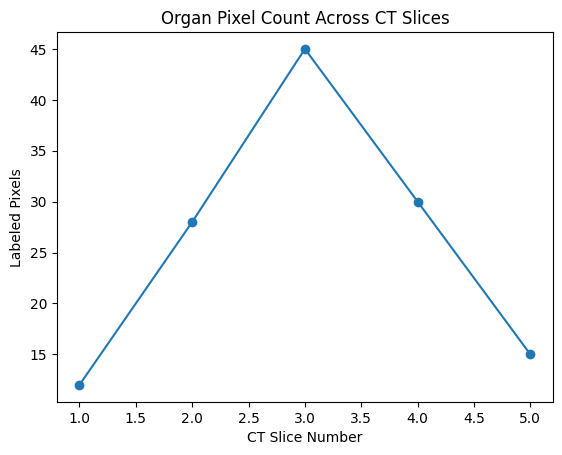

In [33]:
import matplotlib.pyplot as plt

slice_numbers = np.array([1, 2, 3, 4, 5])
organ_pixels = np.array([12, 28, 45, 30, 15])

plt.plot(slice_numbers, organ_pixels, marker="o")
plt.title("Organ Pixel Count Across CT Slices")
plt.xlabel("CT Slice Number")
plt.ylabel("Labeled Pixels")
plt.show()

<h3><font color="#0E7490"><b>Worked example 2: Compare organ volumes using a Bar Chart (plt.bar)</b></font></h3>
<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">In Worked Example 1, we used a <b>line plot</b> because Slice 1, Slice 2, and Slice 3 are connected in a physical sequence—moving smoothly through the body. But what if you want to compare separate categories, like three different organs (<code>"Aorta"</code>, <code>"Kidney"</code>, <code>"Liver"</code>) or three separate patient scans (<code>"CT_001"</code>, <code>"CT_002"</code>, <code>"CT_003"</code>)?</font></p>

<p><font color="#334155">Connecting separate organs with a line does not make sense, because there is no such thing as "halfway between an aorta and a kidney." Instead, we use a <b>bar chart</b> with <code>plt.bar(categories, values)</code>. Each category gets its own standalone vertical bar, and the height of the bar shows its value.</font></p>

<ul>
  <li><font color="#334155"><b>First input (X-axis categories):</b> A list of text labels, such as <code>["Aorta", "Kidney", "Liver"]</code>.</font></li>
  <li><font color="#334155"><b>Second input (Y-axis bar heights):</b> A list or NumPy array of numbers, such as <code>np.array([45, 150, 1400])</code>.</font></li>
  <li><font color="#0E7490"><b>Optional style tip:</b></font> <font color="#334155">You can pass <code>color="teal"</code> (or a hex color code like <code>color="#0E7490"</code>) inside <code>plt.bar()</code> to choose the color of the bars.</font></li>
</ul>

<p><font color="#A34F00"><b>Remember:</b></font> <font color="#A34F00">The number of text labels on the X-axis must match the number of values on the Y-axis (3 names = 3 heights). Always finish with <code>plt.show()</code> to display the clean plot.</font></p>
<p><font color="#334155">Try it:</font> Run the next cell. <font color="#0E7490"><b>Expected output:</b></font> A bar chart with three bars comparing the fictional volumes (in mL) of the Aorta (45), Kidney (150), and Liver (1400).</p>

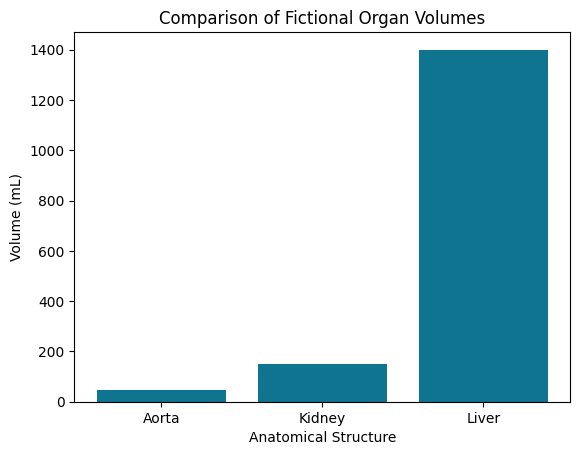

In [34]:
organs = ["Aorta", "Kidney", "Liver"]
volumes_ml = np.array([45, 150, 1400])

plt.bar(organs, volumes_ml, color="#0E7490")
plt.title("Comparison of Fictional Organ Volumes")
plt.xlabel("Anatomical Structure")
plt.ylabel("Volume (mL)")
plt.show()

<h3><font color="#7135B5"><b>Your turn: 5 exercises</b></font></h3>
<p><font color="#7135B5">Start with Exercise 5.1 and work toward Exercise 5.5.</font> <font color="#334155">Because you already ran <code>import matplotlib.pyplot as plt</code> in Worked Example 1, <code>plt</code> is ready to use in every cell below. Always remember to put <code>plt.show()</code> on the last line so your chart displays cleanly.</font></p>

<p><font color="#7135B5"><b>Exercise 5.1 — Draw your first line plot (Aorta Diameter Across Slices)</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Using the provided arrays <code>slices = np.array([1, 2, 3, 4])</code> and <code>diameters_mm = np.array([20, 22, 23, 21])</code>, draw a line plot with circle markers (<code>marker="o"</code>) and display it with <code>plt.show()</code>.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">In <code>plt.plot(x, y, marker="o")</code>, the first array (<code>slices</code>) tells Python where to place each point horizontally (left to right), and the second array (<code>diameters_mm</code>) tells Python how high to place each point vertically (bottom to top).</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> A line chart with 4 connected dots starting at height 20, rising to 23 at slice 3, and dipping to 21 at slice 4.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Beneath the starter arrays, write <code>plt.plot(slices, diameters_mm, marker="o")</code>. &nbsp; 2. On the next line, write <code>plt.show()</code>.</font></p>

In [35]:
# Exercise 5.1 — Draw your first line plot (Aorta Diameter Across Slices)
slices = np.array([1, 2, 3, 4])
diameters_mm = np.array([20, 22, 23, 21])
# Write your Python code below.

<p><font color="#7135B5"><b>Exercise 5.2 — Draw a bar chart of dataset groups (plt.bar)</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> In AI research, scans are split into three separate groups: <code>groups = ["Training", "Validation", "Test"]</code>. Given the scan counts <code>counts = np.array([12, 4, 4])</code>, create a bar chart using <code>plt.bar()</code> and display it.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Because <code>"Training"</code>, <code>"Validation"</code>, and <code>"Test"</code> are separate categories of data rather than a continuous timeline, a bar chart lets you immediately compare how many CT scans are in each bucket.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> A bar chart with 3 vertical bars of heights 12, 4, and 4.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Write <code>plt.bar(groups, counts)</code>. &nbsp; 2. On the next line, write <code>plt.show()</code>.</font></p>

In [36]:
# Exercise 5.2 — Draw a bar chart of dataset groups (plt.bar)
groups = ["Training", "Validation", "Test"]
counts = np.array([12, 4, 4])
# Write your Python code below.

<p><font color="#7135B5"><b>Exercise 5.3 — Add a title and axis labels to a research plot</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Plot the AI model's segmentation score across 4 training steps using <code>steps = np.array([1, 2, 3, 4])</code> and <code>scores = np.array([0.60, 0.75, 0.85, 0.90])</code> with <code>marker="o"</code>. Add the title <code>"AI Segmentation Score Over Time"</code>, the X-axis label <code>"Training Step"</code>, and the Y-axis label <code>"Score"</code>, then display the plot.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">On a symposium poster, a chart without labels is impossible for judges to interpret. Adding <code>plt.title()</code>, <code>plt.xlabel()</code>, and <code>plt.ylabel()</code> turns a raw sketch into a clear scientific figure.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> An upward-sloping line plot from 0.60 to 0.90 with a title at the top and labels on both axes.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. <code>plt.plot(steps, scores, marker="o")</code> &nbsp; 2. <code>plt.title("AI Segmentation Score Over Time")</code> &nbsp; 3. <code>plt.xlabel("Training Step")</code> &nbsp; 4. <code>plt.ylabel("Score")</code> &nbsp; 5. <code>plt.show()</code>.</font></p>

In [37]:
# Exercise 5.3 — Add a title and axis labels to a research plot
steps = np.array([1, 2, 3, 4])
scores = np.array([0.60, 0.75, 0.85, 0.90])
# Write your Python code below.

<p><font color="#7135B5"><b>Exercise 5.4 — Calculate AI volume errors with NumPy and plot them as a bar chart</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> For three scans <code>cases = ["CT_001", "CT_002", "CT_003"]</code>, you are given <code>reference_ml = np.array([100, 150, 200])</code> and <code>ai_ml = np.array([104, 138, 202])</code>. First, compute the absolute error array using <code>errors = np.abs(ai_ml - reference_ml)</code>. Then, plot a bar chart of <code>cases</code> vs. <code>errors</code> with a title and Y-axis label <code>"Absolute Error (mL)"</code>.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">This exercise combines Lesson 1 (fast NumPy math) with Lesson 5 (visualization). Once you plot the error bars (`4 mL`, `12 mL`, and `2 mL`), your eyes immediately spot that <code>CT_002</code> had the largest error and needs closer inspection in 3D Slicer!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> A bar chart showing three bars of heights <code>4</code>, <code>12</code>, and <code>2</code> for <code>CT_001</code>, <code>CT_002</code>, and <code>CT_003</code>.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Calculate <code>errors = np.abs(ai_ml - reference_ml)</code>. &nbsp; 2. Call <code>plt.bar(cases, errors)</code>. &nbsp; 3. Add <code>plt.title("AI Volume Error by Case")</code> and <code>plt.ylabel("Absolute Error (mL)")</code>. &nbsp; 4. Call <code>plt.show()</code>.</font></p>

In [38]:
# Exercise 5.4 — Calculate AI volume errors with NumPy and plot them as a bar chart
cases = ["CT_001", "CT_002", "CT_003"]
reference_ml = np.array([100, 150, 200])
ai_ml = np.array([104, 138, 202])
# Write your Python code below.

<p><font color="#7135B5"><b>Exercise 5.5 — Plot Reference vs. AI measurements on the same chart</b></font> &nbsp; <font color="#7135B5">(Challenge)</font></p>
<p><font color="#334155"><b>Goal:</b> Across 4 CT slices (<code>slices = np.array([1, 2, 3, 4])</code>), compare the true organ pixel counts <code>reference = np.array([10, 30, 35, 15])</code> against the AI predictions <code>ai = np.array([12, 27, 38, 14])</code> by plotting <b>both lines on the same graph</b>.</font></p>
<p><font color="#0E7490"><b>Intuitive idea (How to draw two lines on one chart):</b></font> <font color="#334155">If you call <code>plt.plot()</code> <b>twice</b> before calling <code>plt.show()</code>, Python draws both lines on the exact same canvas in different colors! To tell the two lines apart:</font></p>
<ol>
  <li><font color="#334155">Add <code>label="Reference"</code> inside the first <code>plt.plot()</code> call.</font></li>
  <li><font color="#334155">Add <code>label="AI"</code> inside the second <code>plt.plot()</code> call.</font></li>
  <li><font color="#0E7490">Call <code>plt.legend()</code> right before <code>plt.show()</code> to display a color key box in the corner.</font></li>
</ol>
<p><font color="#0E7490"><b>Expected output:</b></font> A single chart with two colored lines (Reference and AI) tracking closely together across Slices 1 to 4, complete with a legend box.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. <code>plt.plot(slices, reference, marker="o", label="Reference")</code> &nbsp; 2. <code>plt.plot(slices, ai, marker="o", label="AI")</code> &nbsp; 3. Add a title and axis labels. &nbsp; 4. <code>plt.legend()</code> &nbsp; 5. <code>plt.show()</code>.</font></p>

In [39]:
# Exercise 5.5 — Plot Reference vs. AI measurements on the same chart
slices = np.array([1, 2, 3, 4])
reference = np.array([10, 30, 35, 15])
ai = np.array([12, 27, 38, 14])
# Write your Python code below.

<hr>
<h2><font color="#1D4ED8"><b>6. Turn Numbers into Pictures: Grayscale Images and Segmentation Overlays</b></font></h2>

<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">In Lesson 3 and Lesson 4, you saw that a 2D medical image is just a grid of numbers. How does software like 3D Slicer or Python turn that grid of numbers into an actual picture you can see with your eyes? It uses a command called <b><code>plt.imshow()</code></b> (short for <b>image show</b>).</font></p>

<p><font color="#334155">Think of <code>plt.imshow()</code> as a paint-by-numbers artist. It looks at every number in your 2D NumPy array and paints a square pixel at that exact row and column. When we set the color map to grayscale using <b><code>cmap="gray"</code></b>:</font></p>
<ul>
  <li><font color="#334155"><b>Lowest numbers (such as <code>0</code>):</b> Painted <b>pure black</b> (like air or background in a CT scan).</font></li>
  <li><font color="#0E7490"><b>Middle numbers (such as <code>40</code> to <code>60</code>):</b> Painted <b>shades of gray</b> (like muscle, liver, or soft tissue).</font></li>
  <li><font color="#177345"><b>Highest numbers (such as <code>100</code>):</b> Painted <b>pure white</b> (like dense bone or a contrast-filled aorta).</font></li>
</ul>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:8px;">
<tr style="background:#eaf3ff">
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Matplotlib Image Tool</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>What it does</b></font></th>
</tr>
<tr>
  <td style="padding:7px"><code>plt.imshow(grid, cmap="gray")</code></td>
  <td style="padding:7px">Displays a 2D NumPy array as a black-and-white (grayscale) image.</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><code>plt.colorbar()</code></td>
  <td style="padding:7px">Adds a vertical brightness legend bar on the right side showing which shade of gray matches which number.</td>
</tr>
<tr>
  <td style="padding:7px"><code>plt.subplot(1, 2, 1)</code></td>
  <td style="padding:7px">Places multiple images side by side in <code>1</code> row and <code>2</code> columns (<code>1</code> = left image, <code>2</code> = right image).</td>
</tr>
</table>

<p><font color="#A34F00"><b>Why do we specify <code>cmap="gray"</code>?</b></font> <font color="#334155">If you forget <code>cmap="gray"</code>, Matplotlib uses its default rainbow-like color map (purple, blue, green, yellow). While colorful maps are great for heatmaps, doctors and researchers view CT scans in grayscale (<code>cmap="gray"</code>).</font></p>

<h3><font color="#0E7490"><b>Worked example 1: Display a 5×5 array as a grayscale CT slice</b></font></h3>
<p><font color="#334155">Let's build a 5×5 fictional CT slice: the outer border is black background (<code>0</code>), the middle 3×3 ring is gray soft tissue (<code>50</code>), and the very center pixel at <code>[2, 2]</code> is a bright white blood vessel (<code>100</code>). Watch how <code>plt.imshow()</code> turns those numbers into a picture!</font></p>
<p><font color="#334155">Try it:</font> Run the next cell. <font color="#0E7490"><b>Expected output:</b></font> A 5×5 grayscale square image with a black border, a gray middle ring, a bright white center square, and a brightness colorbar on the right.</p>

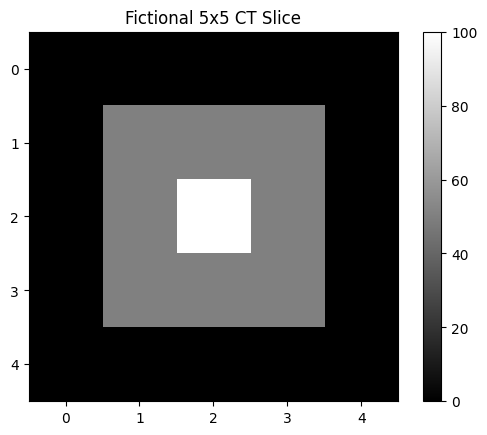

In [40]:
ct_slice = np.array([
    [0,  0,   0,  0, 0],
    [0, 50,  50, 50, 0],
    [0, 50, 100, 50, 0],
    [0, 50,  50, 50, 0],
    [0,  0,   0,  0, 0]
])

plt.imshow(ct_slice, cmap="gray")
plt.title("Fictional 5x5 CT Slice")
plt.colorbar()
plt.show()

<h3><font color="#0E7490"><b>Worked example 2: Compare a CT slice and its segmentation mask side by side (plt.subplot)</b></font></h3>
<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">In medical AI research, you rarely look at a segmentation mask by itself—you want to see the <b>original CT scan</b> and the <b>segmentation mask</b> right next to each other to verify that the mask lines up with the true organ boundary. Matplotlib lets you put two images side by side in a single figure using <b><code>plt.subplot(rows, columns, position)</code></b>.</font></p>

<p><font color="#334155">Think of <code>plt.subplot(1, 2, ...)</code> as a <b>double picture frame</b> with <code>1</code> row and <code>2</code> side-by-side slots:</font></p>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:8px;text-align:center;">
<tr style="background:#eaf3ff">
  <th style="padding:8px;width:50%"><font color="#1D4ED8"><b>Left Slot: <code>plt.subplot(1, 2, 1)</code></b></font></th>
  <th style="padding:8px;width:50%"><font color="#1D4ED8"><b>Right Slot: <code>plt.subplot(1, 2, 2)</code></b></font></th>
</tr>
<tr>
  <td style="padding:10px">
    <b>1</b> row of images, <b>2</b> columns wide, <b>1st</b> image (Left)<br>
    <font color="#0E7490">Draws the original grayscale <b>CT Slice</b></font>
  </td>
  <td style="padding:10px">
    <b>1</b> row of images, <b>2</b> columns wide, <b>2nd</b> image (Right)<br>
    <font color="#177345">Draws the <b>Binary Mask</b> (<code>0</code> = black, <code>1</code> = white)</font>
  </td>
</tr>
</table>

<p><font color="#A34F00"><b>Remember:</b></font> <font color="#A34F00">Call <code>plt.subplot(1, 2, 1)</code> before drawing the left image, and call <code>plt.subplot(1, 2, 2)</code> before drawing the right image. Only call <code>plt.show()</code> <b>once at the very end</b> after both slots are filled!</font></p>
<p><font color="#334155">Try it:</font> Run the next cell. <font color="#0E7490"><b>Expected output:</b></font> Two 5×5 images side by side: the left image shows the CT slice in shades of gray, and the right image shows the segmented center organ in pure black (<code>0</code>) and white (<code>1</code>).</p>

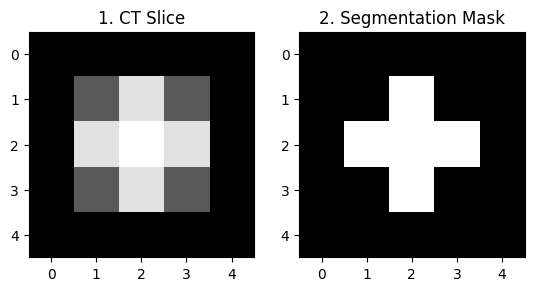

In [41]:
ct_slice = np.array([
    [10, 10, 10, 10, 10],
    [10, 40, 85, 40, 10],
    [10, 85, 95, 85, 10],
    [10, 40, 85, 40, 10],
    [10, 10, 10, 10, 10]
])

# Segment the bright cross-shaped structure (intensity >= 80)
organ_mask = (ct_slice >= 80).astype(int)

# Left image (Slot 1): Original CT slice
plt.subplot(1, 2, 1)
plt.imshow(ct_slice, cmap="gray")
plt.title("1. CT Slice")

# Right image (Slot 2): Binary mask
plt.subplot(1, 2, 2)
plt.imshow(organ_mask, cmap="gray")
plt.title("2. Segmentation Mask")

plt.show()

<h3><font color="#7135B5"><b>Your turn: 5 exercises</b></font></h3>
<p><font color="#7135B5">Start with Exercise 6.1 and work toward Exercise 6.5.</font> <font color="#334155">Remember that <code>plt.imshow(grid, cmap="gray")</code> paints low numbers dark and high numbers bright, and <code>plt.show()</code> displays the finished figure.</font></p>

<p><font color="#7135B5"><b>Exercise 6.1 — Display a 3×3 array as a grayscale image (plt.imshow)</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Using the provided 3×3 array <code>mini_image</code>, display it as a grayscale image using <code>plt.imshow(mini_image, cmap="gray")</code>, add the title <code>"3x3 Grayscale Image"</code>, and call <code>plt.show()</code>.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Look at the numbers in <code>mini_image</code> before running your code: the top row is <code>0</code> (black), the middle row is <code>50</code> (medium gray), and the bottom row is <code>100</code> (bright white). Your image should look like three horizontal stripes transitioning from black to gray to white!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> A 3×3 image with a black top row, a gray middle row, and a white bottom row.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Write <code>plt.imshow(mini_image, cmap="gray")</code>. &nbsp; 2. Write <code>plt.title("3x3 Grayscale Image")</code>. &nbsp; 3. Write <code>plt.show()</code>.</font></p>

In [42]:
# Exercise 6.1 — Display a 3x3 array as a grayscale image (plt.imshow)
mini_image = np.array([
    [0,   0,   0],
    [50,  50,  50],
    [100, 100, 100]
])
# Write your Python code below.

<p><font color="#7135B5"><b>Exercise 6.2 — Build and display a binary mask with a colorbar</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Start with a 4×4 blank mask of zeros (<code>mask = np.zeros((4, 4), dtype=int)</code>) and set the center 2×2 square (<code>mask[1:3, 1:3] = 1</code>) to <code>1</code>. Display <code>mask</code> using <code>plt.imshow(mask, cmap="gray")</code>, add a brightness legend with <code>plt.colorbar()</code>, and call <code>plt.show()</code>.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">In Lesson 4, you printed this exact 4×4 mask as raw <code>0</code>s and <code>1</code>s. Now, when you pass it to <code>plt.imshow()</code>, all the <code>0</code>s become a black background frame and the 2×2 block of <code>1</code>s becomes a bright white square in the middle.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> A 4×4 image showing a white 2×2 square in the center surrounded by a black border, with a colorbar on the right ranging from <code>0.0</code> to <code>1.0</code>.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Create <code>mask = np.zeros((4, 4), dtype=int)</code> and set <code>mask[1:3, 1:3] = 1</code>. &nbsp; 2. Call <code>plt.imshow(mask, cmap="gray")</code>. &nbsp; 3. Call <code>plt.colorbar()</code>. &nbsp; 4. Call <code>plt.show()</code>.</font></p>

In [43]:
# Exercise 6.2 — Build and display a binary mask with a colorbar
# Write your Python code below.

<p><font color="#7135B5"><b>Exercise 6.3 — Crop a Region of Interest (ROI) and display the zoomed-in image</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> From the provided 4×4 <code>ct_slice</code>, slice out the center 2×2 organ region (<code>roi = ct_slice[1:3, 1:3]</code>), display <code>roi</code> using <code>plt.imshow(roi, cmap="gray")</code> with the title <code>"Cropped 2x2 Organ ROI"</code>, add <code>plt.colorbar()</code>, and call <code>plt.show()</code>.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">When you crop a 2D array with slicing (<code>[1:3, 1:3]</code>) and pass that smaller array to <code>plt.imshow()</code>, it acts just like zooming in with a magnifying glass on the organ!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> A 2×2 grayscale image showing the 4 organ pixels (ranging in brightness from 70 in the top-left to 100 in the bottom-right) with a colorbar.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Write <code>roi = ct_slice[1:3, 1:3]</code>. &nbsp; 2. Write <code>plt.imshow(roi, cmap="gray")</code>. &nbsp; 3. Write <code>plt.title("Cropped 2x2 Organ ROI")</code>. &nbsp; 4. Write <code>plt.colorbar()</code> and <code>plt.show()</code>.</font></p>

In [44]:
# Exercise 6.3 — Crop a Region of Interest (ROI) and display the zoomed-in image
ct_slice = np.array([
    [0,  0,   0, 0],
    [0, 70,  80, 0],
    [0, 90, 100, 0],
    [0,  0,   0, 0]
])
# Write your Python code below.

<p><font color="#7135B5"><b>Exercise 6.4 — Compare Reference Mask vs. AI Mask side by side (plt.subplot)</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Two 4×4 binary masks are provided below: <code>reference_mask</code> and <code>ai_mask</code>. Use <code>plt.subplot(1, 2, 1)</code> to display <code>reference_mask</code> on the left (titled <code>"Reference Mask"</code>) and <code>plt.subplot(1, 2, 2)</code> to display <code>ai_mask</code> on the right (titled <code>"AI Mask"</code>), both with <code>cmap="gray"</code>.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Look closely at the two images once they appear: the Reference Mask is a clean 2×2 white square, while the AI Mask missed one pixel in the bottom-right corner of the organ (Row 2, Column 2). Visual side-by-side comparison makes segmentation mistakes easy to see.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> Two 4×4 black-and-white images side by side: the left shows 4 white pixels in the center, and the right shows 3 white pixels in the center.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. <code>plt.subplot(1, 2, 1)</code> → <code>plt.imshow(reference_mask, cmap="gray")</code> → <code>plt.title("Reference Mask")</code>. &nbsp; 2. <code>plt.subplot(1, 2, 2)</code> → <code>plt.imshow(ai_mask, cmap="gray")</code> → <code>plt.title("AI Mask")</code>. &nbsp; 3. Finish with <code>plt.show()</code>.</font></p>

In [45]:
# Exercise 6.4 — Compare Reference Mask vs. AI Mask side by side (plt.subplot)
reference_mask = np.array([
    [0, 0, 0, 0],
    [0, 1, 1, 0],
    [0, 1, 1, 0],
    [0, 0, 0, 0]
])
ai_mask = np.array([
    [0, 0, 0, 0],
    [0, 1, 1, 0],
    [0, 1, 0, 0],
    [0, 0, 0, 0]
])
# Write your Python code below.

<p><font color="#7135B5"><b>Exercise 6.5 — Build and visualize a 3-panel Segmentation Error Map</b></font> &nbsp; <font color="#7135B5">(Challenge)</font></p>
<p><font color="#334155"><b>Goal:</b> Using the provided <code>reference_mask</code> and <code>ai_mask</code>:</font></p>
<ol>
  <li><font color="#334155">Calculate the pixel-by-pixel mistake grid: <code>error_map = np.abs(reference_mask - ai_mask)</code> and print the total number of mismatched pixels using <code>print("Mismatched pixels:", error_map.sum())</code>.</font></li>
  <li><font color="#334155">Use a <b>1-row, 3-column</b> subplot layout (<code>plt.subplot(1, 3, 1)</code>, <code>plt.subplot(1, 3, 2)</code>, and <code>plt.subplot(1, 3, 3)</code>) to display <code>reference_mask</code>, <code>ai_mask</code>, and <code>error_map</code> side by side in grayscale.</font></li>
</ol>
<p><font color="#0E7490"><b>Intuitive idea (How an Error Map works):</b></font> <font color="#334155">When you subtract two binary masks and take the absolute value (<code>np.abs(reference_mask - ai_mask)</code>):</font></p>
<ul>
  <li><font color="#334155">Everywhere the AI and Reference <b>agree</b> (<code>1 - 1 = 0</code> or <code>0 - 0 = 0</code>), the error map is <b><code>0</code> (black)</b>.</font></li>
  <li><font color="#177345">Everywhere the AI and Reference <b>disagree</b> (<code>|1 - 0| = 1</code> or <code>|0 - 1| = 1</code>), the error map lights up as <b><code>1</code> (bright white)</b>!</font></li>
</ul>
<p><font color="#334155">This 3-panel figure (Reference vs. AI vs. Error Map) is one of the most effective visuals you can put on your Spring Symposium research poster!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> The printed line <code>Mismatched pixels: 2</code>, followed by three side-by-side images where the third image (<code>Error Map</code>) lights up only at the 2 mismatched pixels.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Compute <code>error_map = np.abs(reference_mask - ai_mask)</code> and print <code>"Mismatched pixels:", error_map.sum()</code>. &nbsp; 2. Use <code>plt.subplot(1, 3, 1)</code> for <code>reference_mask</code>, <code>plt.subplot(1, 3, 2)</code> for <code>ai_mask</code>, and <code>plt.subplot(1, 3, 3)</code> for <code>error_map</code>. &nbsp; 3. Call <code>plt.show()</code> at the end.</font></p>

In [46]:
# Exercise 6.5 — Build and visualize a 3-panel Segmentation Error Map
reference_mask = np.array([
    [0, 0, 0, 0],
    [0, 1, 1, 0],
    [0, 1, 1, 0],
    [0, 0, 0, 0]
])
ai_mask = np.array([
    [0, 0, 0, 0],
    [0, 1, 1, 0],
    [0, 1, 0, 1],
    [0, 0, 0, 0]
])
# Write your Python code below.

<hr>
<h1><font color="#177345"><b>Solutions — Check After You Try</b></font></h1>
<p><font color="#177345"><b>Every exercise has a complete, independent solution below.</b></font> <font color="#334155">For example, you can run Solution <code>3.5</code> without running Solution <code>3.4</code> first. Each solution includes a brief explanation of <i>why</i> the code works. If your code produces the exact same output using a slightly different variable name, that is completely fine!</font></p>

<h2><font color="#177345"><b>1. Solutions: 1D NumPy Arrays</b></font></h2>

<p><font color="#177345"><b>Solution 1.1 — Create your first NumPy array</b></font> &nbsp; <font color="#0E7490"><b>Expected:</b></font> <code>[10 20 30]</code></p>
<p><font color="#334155"><b>Why this works:</b> Passing the Python list <code>[10, 20, 30]</code> inside <code>np.array(...)</code> converts the list into a 1D NumPy array. When printed, NumPy displays the numbers without commas.</font></p>

In [47]:
# Solution 1.1: Create your first NumPy array
import numpy as np

slice_counts = np.array([10, 20, 30])
print(slice_counts)

[10 20 30]


<p><font color="#177345"><b>Solution 1.2 — Multiply every number at once (Voxel Volumes)</b></font> &nbsp; <font color="#0E7490"><b>Expected:</b></font> <code>[200 500 800]</code></p>
<p><font color="#334155"><b>Why this works:</b> Multiplying a NumPy array by <code>2</code> performs vectorized math—it multiplies Index 0 (<code>100 * 2</code>), Index 1 (<code>250 * 2</code>), and Index 2 (<code>400 * 2</code>) simultaneously without needing a <code>for</code> loop.</font></p>

In [48]:
# Solution 1.2: Multiply every number at once (Voxel Volumes)
import numpy as np

voxel_counts = np.array([100, 250, 400])
volumes_mm3 = voxel_counts * 2
print(volumes_mm3)

[200 500 800]


<p><font color="#177345"><b>Solution 1.3 — Convert cubic millimeters to milliliters</b></font> &nbsp; <font color="#0E7490"><b>Expected:</b></font> <code>[1.5 2.5 4. ]</code></p>
<p><font color="#334155"><b>Why this works:</b> Because <code>1,000 mm³ = 1 mL</code>, dividing the array by <code>1000</code> converts all three measurements at once. In Python, division with <code>/</code> always produces decimal numbers (floats).</font></p>

In [49]:
# Solution 1.3: Convert cubic millimeters to milliliters
import numpy as np

volumes_mm3 = np.array([1500, 2500, 4000])
volumes_ml = volumes_mm3 / 1000
print(volumes_ml)

[1.5 2.5 4. ]


<p><font color="#177345"><b>Solution 1.4 — Add two arrays together (Left + Right Kidney Volumes)</b></font> &nbsp; <font color="#0E7490"><b>Expected:</b></font> <code>[275 305 325]</code></p>
<p><font color="#334155"><b>Why this works:</b> Because both arrays have the exact same length (3 items), the <code>+</code> operator pairs up matching positions (<code>140 + 135</code>, <code>155 + 150</code>, and <code>160 + 165</code>) to compute the total kidney volume for each scan.</font></p>

In [50]:
# Solution 1.4: Add two arrays together (Left + Right Kidney Volumes)
import numpy as np

left_kidney = np.array([140, 155, 160])
right_kidney = np.array([135, 150, 165])
total_kidney = left_kidney + right_kidney
print(total_kidney)

[275 305 325]


<p><font color="#177345"><b>Solution 1.5 — Calculate percentage error across three scans at once</b></font> &nbsp; <font color="#0E7490"><b>Expected:</b></font> <code>[10.  4. 10.]</code></p>
<p><font color="#334155"><b>Why this works:</b> First, <code>np.abs(ai - reference)</code> finds the positive size of the mistake for each scan (<code>[2, 1, 5]</code>). Next, dividing by <code>reference</code> compares each mistake to the true size (<code>[0.10, 0.04, 0.10]</code>), and multiplying by <code>100</code> converts those decimals into percentages.</font></p>

In [51]:
# Solution 1.5: Calculate percentage error across three scans at once
import numpy as np

reference = np.array([20, 25, 50])
ai = np.array([22, 24, 55])
percent_error = np.abs(ai - reference) / reference * 100
print(percent_error)

[10.  4. 10.]


<h2><font color="#177345"><b>2. Solutions: Inspect and Summarize Arrays</b></font></h2>

<p><font color="#177345"><b>Solution 2.1 — Check how many items are in an array (.size and .shape)</b></font> &nbsp; <font color="#0E7490"><b>Expected:</b></font> <code>5</code> and <code>(5,)</code></p>
<p><font color="#334155"><b>Why this works:</b> <code>.size</code> returns the total number of values (<code>5</code>), and <code>.shape</code> returns a tuple showing the length along each dimension (<code>(5,)</code> means a 1D array of 5 elements). Because both are stored properties rather than actions, neither uses parentheses <code>()</code>.</font></p>

In [52]:
# Solution 2.1: Check how many items are in an array (.size and .shape)
import numpy as np

scans = np.array([80, 100, 120, 140, 160])
print(scans.size)
print(scans.shape)

5
(5,)


<p><font color="#177345"><b>Solution 2.2 — Compare whole-number vs. decimal array types (.dtype)</b></font> &nbsp; <font color="#0E7490"><b>Expected:</b></font> <code>int64</code> and <code>float64</code></p>
<p><font color="#334155"><b>Why this works:</b> NumPy automatically inspects the numbers you pass in. Because <code>[1, 2, 3]</code> has no decimal points, NumPy stores it as 64-bit integers (<code>int64</code>). Because <code>[0.5, 1.0, 1.5]</code> contains decimal points, NumPy stores it as 64-bit floating-point numbers (<code>float64</code>).</font></p>

In [53]:
# Solution 2.2: Compare whole-number vs. decimal array types (.dtype)
import numpy as np

counts = np.array([1, 2, 3])
spacings = np.array([0.5, 1.0, 1.5])
print(counts.dtype)
print(spacings.dtype)

int64
float64


<p><font color="#177345"><b>Solution 2.3 — Calculate the total and average volume (.sum and .mean)</b></font> &nbsp; <font color="#0E7490"><b>Expected:</b></font> <code>600</code> and <code>150.0</code></p>
<p><font color="#334155"><b>Why this works:</b> <code>volumes.sum()</code> adds all four numbers together (<code>120 + 150 + 180 + 150 = 600</code>), and <code>volumes.mean()</code> divides that total by the number of items (<code>600 / 4 = 150.0</code>).</font></p>

In [54]:
# Solution 2.3: Calculate the total and average volume (.sum and .mean)
import numpy as np

volumes = np.array([120, 150, 180, 150])
print(volumes.sum())
print(volumes.mean())

600
150.0


<p><font color="#177345"><b>Solution 2.4 — Find the smallest, largest, and spread of measurements (.min and .max)</b></font> &nbsp; <font color="#0E7490"><b>Expected:</b></font> <code>19.5</code>, <code>26.5</code>, and <code>7.0</code></p>
<p><font color="#334155"><b>Why this works:</b> <code>diameters.min()</code> finds the lowest value (<code>19.5</code>), <code>diameters.max()</code> finds the highest value (<code>26.5</code>), and subtracting the minimum from the maximum gives the total spread across the dataset (<code>26.5 - 19.5 = 7.0</code>).</font></p>

In [55]:
# Solution 2.4: Find the smallest, largest, and spread of measurements (.min and .max)
import numpy as np

diameters = np.array([19.5, 22.0, 26.5, 21.0])
print(diameters.min())
print(diameters.max())
print(diameters.max() - diameters.min())

19.5
26.5
7.0


<p><font color="#177345"><b>Solution 2.5 — Compute Mean Absolute Error (MAE) across four scans</b></font> &nbsp; <font color="#0E7490"><b>Expected:</b></font> <code>7.5</code></p>
<p><font color="#334155"><b>Why this works:</b> First, <code>np.abs(ai - reference)</code> computes the positive error size for each scan: <code>[5, 10, 10, 5]</code>. Calling <code>.mean()</code> on that error array averages those four numbers (<code>30 / 4 = 7.5</code>) so positive and negative errors never cancel each other out.</font></p>

In [56]:
# Solution 2.5: Compute Mean Absolute Error (MAE) across four scans
import numpy as np

ai = np.array([105, 140, 210, 95])
reference = np.array([100, 150, 200, 100])
errors = np.abs(ai - reference)
print(errors.mean())

7.5


<h2><font color="#177345"><b>3. Solutions: 2D Arrays, Grids, and Slicing</b></font></h2>

<p><font color="#177345"><b>Solution 3.1 — Build a 2×3 pixel grid and check its shape</b></font> &nbsp; <font color="#0E7490"><b>Expected:</b></font> <code>(2, 3)</code> and <code>6</code></p>
<p><font color="#334155"><b>Why this works:</b> Putting two 3-item row lists inside outer square brackets creates a 2D array with 2 rows and 3 columns. <code>grid.shape</code> reports <code>(rows, columns)</code> as <code>(2, 3)</code>, and <code>grid.size</code> reports the total number of pixels (<code>2 × 3 = 6</code>).</font></p>

In [57]:
# Solution 3.1: Build a 2x3 pixel grid and check its shape
import numpy as np

grid = np.array([
    [10, 20, 30],
    [40, 50, 60]
])
print(grid.shape)
print(grid.size)

(2, 3)
6


<p><font color="#177345"><b>Solution 3.2 — Read specific pixels by row and column</b></font> &nbsp; <font color="#0E7490"><b>Expected:</b></font> <code>85</code> and <code>35</code></p>
<p><font color="#334155"><b>Why this works:</b> In <code>image[row, column]</code>, counting starts at <code>0</code>. The center pixel <code>85</code> is in the middle row (Row <code>1</code>) and middle column (Column <code>1</code>), so we write <code>image[1, 1]</code>. The bottom-left pixel <code>35</code> is in the bottom row (Row <code>2</code>) and leftmost column (Column <code>0</code>), so we write <code>image[2, 0]</code>.</font></p>

In [58]:
# Solution 3.2: Read specific pixels by row and column
import numpy as np

image = np.array([
    [5,  10, 15],
    [20, 85, 30],
    [35, 40, 45]
])
print(image[1, 1])
print(image[2, 0])

85
35


<p><font color="#177345"><b>Solution 3.3 — Grab an entire row and an entire column</b></font> &nbsp; <font color="#0E7490"><b>Expected:</b></font> <code>[1 2 3]</code> and <code>[3 6 9]</code></p>
<p><font color="#334155"><b>Why this works:</b> A single colon <code>:</code> tells NumPy to select every index along that direction. <code>image[0, :]</code> selects Row <code>0</code> across all columns (<code>[1, 2, 3]</code>), while <code>image[:, 2]</code> selects all rows down Column <code>2</code> (<code>[3, 6, 9]</code>).</font></p>

In [59]:
# Solution 3.3: Grab an entire row and an entire column
import numpy as np

image = np.array([
    [1, 2, 3],
    [4, 5, 6],
    [7, 8, 9]
])
print(image[0, :])
print(image[:, 2])

[1 2 3]
[3 6 9]


<p><font color="#177345"><b>Solution 3.4 — Crop a 2×2 corner region from a scan</b></font> &nbsp; <font color="#0E7490"><b>Expected:</b></font> <code>[[50 55] [60 65]]</code></p>
<p><font color="#334155"><b>Why this works:</b> Slicing with <code>0:2</code> starts at index <code>0</code> and stops just before index <code>2</code> (giving indices <code>0</code> and <code>1</code>). Applying <code>0:2</code> to both the rows and the columns (<code>scan[0:2, 0:2]</code>) crops out the top-left 2×2 corner.</font></p>

In [60]:
# Solution 3.4: Crop a 2x2 corner region from a scan
import numpy as np

scan = np.array([
    [50, 55, 0],
    [60, 65, 0],
    [0,   0, 0]
])
corner = scan[0:2, 0:2]
print(corner)

[[50 55]
 [60 65]]


<p><font color="#177345"><b>Solution 3.5 — Why cropping matters: Whole-slice average vs. Organ ROI average</b></font> &nbsp; <font color="#0E7490"><b>Expected:</b></font> <code>21.875</code> and <code>87.5</code></p>
<p><font color="#334155"><b>Why this works:</b> <code>ct_slice.mean()</code> averages all 16 pixels (including the 12 background zeros), which pulls the average down to <code>21.875</code>. Cropping the center 2×2 region first with <code>ct_slice[1:3, 1:3]</code> isolates only the four organ pixels (<code>80, 85, 90, 95</code>), whose average is <code>87.5</code>.</font></p>

In [61]:
# Solution 3.5: Why cropping matters: Whole-slice average vs. Organ ROI average
import numpy as np

ct_slice = np.array([
    [0,  0,  0, 0],
    [0, 80, 85, 0],
    [0, 90, 95, 0],
    [0,  0,  0, 0]
])
print(ct_slice.mean())

organ = ct_slice[1:3, 1:3]
print(organ.mean())

21.875
87.5


<h2><font color="#177345"><b>4. Solutions: Blank Canvases, Binary Masks, and Thresholding</b></font></h2>

<p><font color="#177345"><b>Solution 4.1 — Create a blank 3×3 background mask (np.zeros)</b></font> &nbsp; <font color="#0E7490"><b>Expected:</b></font> A 3×3 grid of <code>0</code>s</p>
<p><font color="#334155"><b>Why this works:</b> Passing the shape tuple <code>(3, 3)</code> inside <code>np.zeros((3, 3), dtype=int)</code> creates a 2D array with 3 rows and 3 columns filled with whole-number zeros. Remember that the inner parentheses group the row and column counts together as a single shape input.</font></p>

In [62]:
# Solution 4.1: Create a blank 3x3 background mask (np.zeros)
import numpy as np

blank_mask = np.zeros((3, 3), dtype=int)
print(blank_mask)

[[0 0 0]
 [0 0 0]
 [0 0 0]]


<p><font color="#177345"><b>Solution 4.2 — Create a 2×4 grid of ones and count its pixels (np.ones)</b></font> &nbsp; <font color="#0E7490"><b>Expected:</b></font> A 2×4 grid of <code>1</code>s, followed by <code>8</code></p>
<p><font color="#334155"><b>Why this works:</b> <code>np.ones((2, 4), dtype=int)</code> builds a 2-row by 4-column grid where every pixel is <code>1</code>. Calling <code>.sum()</code> adds all eight <code>1</code>s together to return <code>8</code>.</font></p>

In [63]:
# Solution 4.2: Create a 2x4 grid of ones and count its pixels (np.ones)
import numpy as np

ones_grid = np.ones((2, 4), dtype=int)
print(ones_grid)
print(ones_grid.sum())

[[1 1 1 1]
 [1 1 1 1]]
8


<p><font color="#177345"><b>Solution 4.3 — Draw a horizontal blood vessel across a blank mask</b></font> &nbsp; <font color="#0E7490"><b>Expected:</b></font> Middle row of <code>1</code>s, followed by <code>3</code></p>
<p><font color="#334155"><b>Why this works:</b> After creating a 3×3 grid of zeros, <code>mask[1, :] = 1</code> selects Row <code>1</code> (the middle row) across all columns (<code>:</code>) and replaces those three zeros with <code>1</code>s. Calling <code>mask.sum()</code> counts the <code>3</code> labeled vessel pixels.</font></p>

In [64]:
# Solution 4.3: Draw a horizontal blood vessel across a blank mask
import numpy as np

mask = np.zeros((3, 3), dtype=int)
mask[1, :] = 1
print(mask)
print(mask.sum())

[[0 0 0]
 [1 1 1]
 [0 0 0]]
3


<p><font color="#177345"><b>Solution 4.4 — Segment bright pixels using a threshold</b></font> &nbsp; <font color="#0E7490"><b>Expected:</b></font> <code>[[0 1 0] [1 0 1]]</code> and <code>3</code></p>
<p><font color="#334155"><b>Why this works:</b> The comparison <code>scan &gt;= 50</code> checks every pixel at once and produces <code>True</code> where the intensity is 50 or higher (at <code>65</code>, <code>80</code>, and <code>95</code>) and <code>False</code> everywhere else. Attaching <code>.astype(int)</code> converts <code>True</code> to <code>1</code> and <code>False</code> to <code>0</code>, and <code>mask.sum()</code> counts the <code>3</code> bright pixels.</font></p>

In [65]:
# Solution 4.4: Segment bright pixels using a threshold
import numpy as np

scan = np.array([
    [15, 65, 20],
    [80, 10, 95]
])
mask = (scan >= 50).astype(int)
print(mask)
print(mask.sum())

[[0 1 0]
 [1 0 1]]
3


<p><font color="#177345"><b>Solution 4.5 — Find the overlap between an AI mask and a Reference mask</b></font> &nbsp; <font color="#0E7490"><b>Expected:</b></font> <code>[[1 1] [0 0]]</code> and <code>2</code></p>
<p><font color="#334155"><b>Why this works:</b> When multiplying two binary (<code>0</code>/<code>1</code>) masks element by element, a position only stays <code>1</code> if <b>both</b> masks have a <code>1</code> at that exact spot (<code>1 * 1 = 1</code>). Any spot where one or both masks have a <code>0</code> becomes <code>0</code>. Summing the <code>overlap</code> grid tells us that the AI and reference masks agree on <code>2</code> organ pixels.</font></p>

In [66]:
# Solution 4.5: Find the overlap between an AI mask and a Reference mask
import numpy as np

reference_mask = np.array([
    [1, 1],
    [1, 0]
])
ai_mask = np.array([
    [1, 1],
    [0, 1]
])
overlap = reference_mask * ai_mask
print(overlap)
print(overlap.sum())

[[1 1]
 [0 0]]
2


<h2><font color="#177345"><b>5. Solutions: Simple Visualization with Matplotlib</b></font></h2>

<p><font color="#177345"><b>Solution 5.1 — Draw your first line plot (Aorta Diameter Across Slices)</b></font> &nbsp; <font color="#0E7490"><b>Expected:</b></font> A 4-point line plot with circle markers</p>
<p><font color="#334155"><b>Why this works:</b> <code>plt.plot(slices, diameters_mm, marker="o")</code> places the slice numbers along the horizontal X-axis, places the diameter values along the vertical Y-axis, connects them with a line, and draws a circle dot (<code>"o"</code>) at each measurement. Calling <code>plt.show()</code> renders the finished chart.</font></p>

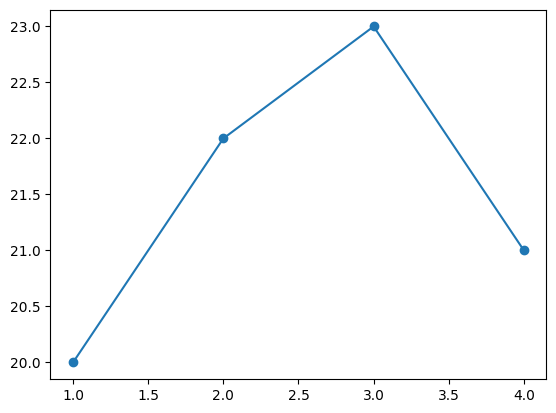

In [67]:
# Solution 5.1: Draw your first line plot (Aorta Diameter Across Slices)
import numpy as np
import matplotlib.pyplot as plt

slices = np.array([1, 2, 3, 4])
diameters_mm = np.array([20, 22, 23, 21])

plt.plot(slices, diameters_mm, marker="o")
plt.show()

<p><font color="#177345"><b>Solution 5.2 — Draw a bar chart of dataset groups (plt.bar)</b></font> &nbsp; <font color="#0E7490"><b>Expected:</b></font> A 3-bar chart with heights <code>12</code>, <code>4</code>, and <code>4</code></p>
<p><font color="#334155"><b>Why this works:</b> Because <code>"Training"</code>, <code>"Validation"</code>, and <code>"Test"</code> are separate categories rather than a continuous sequence, <code>plt.bar(groups, counts)</code> draws one standalone vertical bar for each group whose height matches its scan count.</font></p>

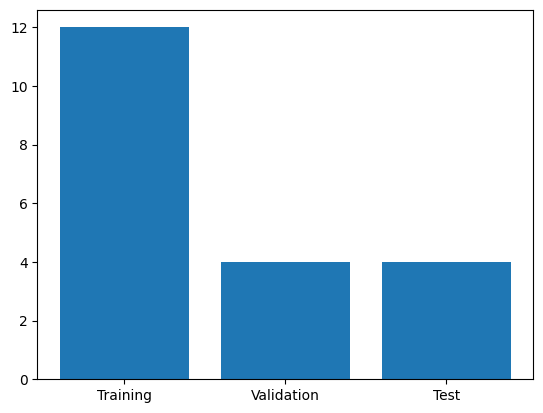

In [68]:
# Solution 5.2: Draw a bar chart of dataset groups (plt.bar)
import numpy as np
import matplotlib.pyplot as plt

groups = ["Training", "Validation", "Test"]
counts = np.array([12, 4, 4])

plt.bar(groups, counts)
plt.show()

<p><font color="#177345"><b>Solution 5.3 — Add a title and axis labels to a research plot</b></font> &nbsp; <font color="#0E7490"><b>Expected:</b></font> Labeled upward-sloping line plot from <code>0.60</code> to <code>0.90</code></p>
<p><font color="#334155"><b>Why this works:</b> After drawing the line with <code>plt.plot()</code>, calling <code>plt.title()</code>, <code>plt.xlabel()</code>, and <code>plt.ylabel()</code> attaches a heading and axis descriptions to the figure before <code>plt.show()</code> displays it.</font></p>

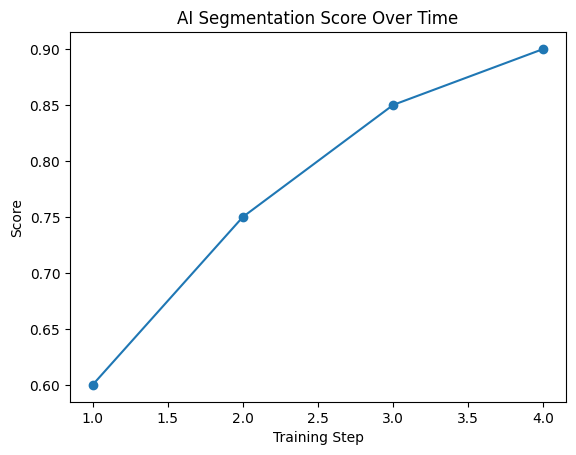

In [69]:
# Solution 5.3: Add a title and axis labels to a research plot
import numpy as np
import matplotlib.pyplot as plt

steps = np.array([1, 2, 3, 4])
scores = np.array([0.60, 0.75, 0.85, 0.90])

plt.plot(steps, scores, marker="o")
plt.title("AI Segmentation Score Over Time")
plt.xlabel("Training Step")
plt.ylabel("Score")
plt.show()

<p><font color="#177345"><b>Solution 5.4 — Calculate AI volume errors with NumPy and plot them as a bar chart</b></font> &nbsp; <font color="#0E7490"><b>Expected:</b></font> A bar chart with bar heights <code>4</code>, <code>12</code>, and <code>2</code></p>
<p><font color="#334155"><b>Why this works:</b> First, <code>np.abs(ai_ml - reference_ml)</code> computes the positive volume error for all three scans at once (<code>[4, 12, 2]</code>). Passing <code>cases</code> and <code>errors</code> into <code>plt.bar()</code> turns those error numbers into a visual comparison where the tallest bar (<code>CT_002</code>) immediately stands out.</font></p>

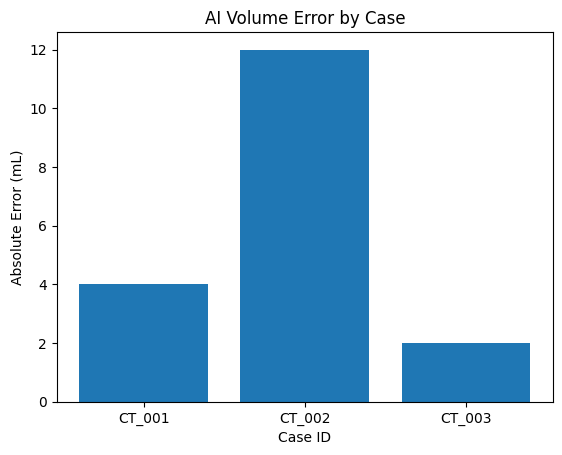

In [70]:
# Solution 5.4: Calculate AI volume errors with NumPy and plot them as a bar chart
import numpy as np
import matplotlib.pyplot as plt

cases = ["CT_001", "CT_002", "CT_003"]
reference_ml = np.array([100, 150, 200])
ai_ml = np.array([104, 138, 202])

errors = np.abs(ai_ml - reference_ml)

plt.bar(cases, errors)
plt.title("AI Volume Error by Case")
plt.xlabel("Case ID")
plt.ylabel("Absolute Error (mL)")
plt.show()

<p><font color="#177345"><b>Solution 5.5 — Plot Reference vs. AI measurements on the same chart</b></font> &nbsp; <font color="#0E7490"><b>Expected:</b></font> Two colored lines on one graph with a legend box</p>
<p><font color="#334155"><b>Why this works:</b> Calling <code>plt.plot()</code> twice before <code>plt.show()</code> draws both curves on the same set of axes. Giving each line a <code>label="..."</code> name and calling <code>plt.legend()</code> creates a color-coded key so anyone reading your chart can tell which line is Reference and which line is AI.</font></p>

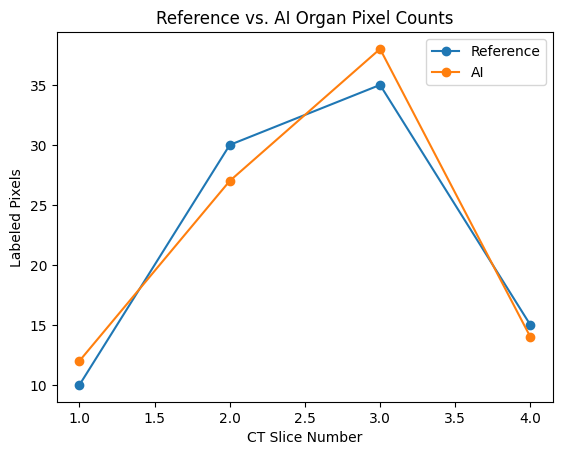

In [71]:
# Solution 5.5: Plot Reference vs. AI measurements on the same chart
import numpy as np
import matplotlib.pyplot as plt

slices = np.array([1, 2, 3, 4])
reference = np.array([10, 30, 35, 15])
ai = np.array([12, 27, 38, 14])

plt.plot(slices, reference, marker="o", label="Reference")
plt.plot(slices, ai, marker="o", label="AI")
plt.title("Reference vs. AI Organ Pixel Counts")
plt.xlabel("CT Slice Number")
plt.ylabel("Labeled Pixels")
plt.legend()
plt.show()

<h2><font color="#177345"><b>6. Solutions: Grayscale Images and Segmentation Overlays</b></font></h2>

<p><font color="#177345"><b>Solution 6.1 — Display a 3×3 array as a grayscale image (plt.imshow)</b></font> &nbsp; <font color="#0E7490"><b>Expected:</b></font> A 3×3 image with black, gray, and white horizontal stripes</p>
<p><font color="#334155"><b>Why this works:</b> <code>plt.imshow(mini_image, cmap="gray")</code> translates each number in the 3×3 array into a pixel shade: <code>0</code> (top row) becomes pure black, <code>50</code> (middle row) becomes medium gray, and <code>100</code> (bottom row) becomes bright white.</font></p>

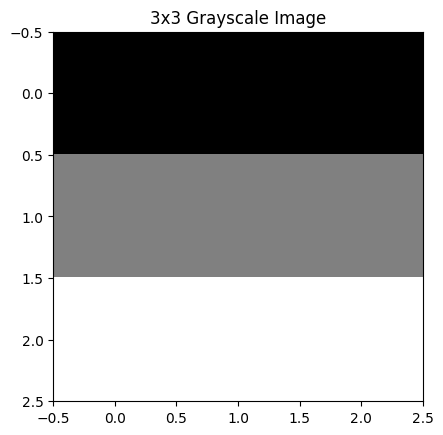

In [72]:
# Solution 6.1: Display a 3x3 array as a grayscale image (plt.imshow)
import numpy as np
import matplotlib.pyplot as plt

mini_image = np.array([
    [0,   0,   0],
    [50,  50,  50],
    [100, 100, 100]
])

plt.imshow(mini_image, cmap="gray")
plt.title("3x3 Grayscale Image")
plt.show()

<p><font color="#177345"><b>Solution 6.2 — Build and display a binary mask with a colorbar</b></font> &nbsp; <font color="#0E7490"><b>Expected:</b></font> A white 2×2 center square on a black 4×4 background with a colorbar</p>
<p><font color="#334155"><b>Why this works:</b> We start with a 4×4 canvas of zeros (<code>0</code> = black background) and slice the center 2×2 region (<code>mask[1:3, 1:3] = 1</code>) so those four pixels become <code>1</code> (white foreground). Adding <code>plt.colorbar()</code> displays the brightness scale from <code>0.0</code> to <code>1.0</code> on the right.</font></p>

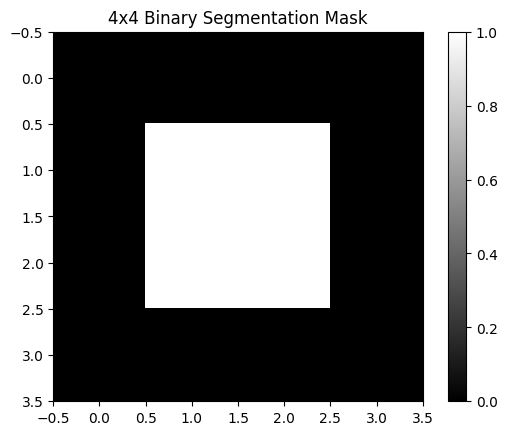

In [73]:
# Solution 6.2: Build and display a binary mask with a colorbar
import numpy as np
import matplotlib.pyplot as plt

mask = np.zeros((4, 4), dtype=int)
mask[1:3, 1:3] = 1

plt.imshow(mask, cmap="gray")
plt.title("4x4 Binary Segmentation Mask")
plt.colorbar()
plt.show()

<p><font color="#177345"><b>Solution 6.3 — Crop a Region of Interest (ROI) and display the zoomed-in image</b></font> &nbsp; <font color="#0E7490"><b>Expected:</b></font> A zoomed-in 2×2 grayscale image with a colorbar from <code>70</code> to <code>100</code></p>
<p><font color="#334155"><b>Why this works:</b> Slicing <code>ct_slice[1:3, 1:3]</code> extracts only Rows 1–2 and Columns 1–2, removing the dark outer border of zeros. Passing that smaller 2×2 <code>roi</code> array into <code>plt.imshow()</code> displays a close-up view of the organ pixels.</font></p>

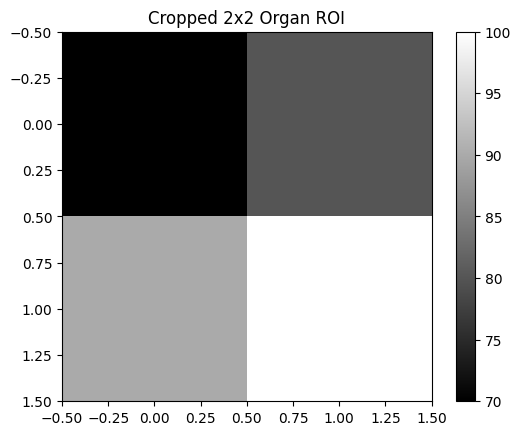

In [74]:
# Solution 6.3: Crop a Region of Interest (ROI) and display the zoomed-in image
import numpy as np
import matplotlib.pyplot as plt

ct_slice = np.array([
    [0,  0,   0, 0],
    [0, 70,  80, 0],
    [0, 90, 100, 0],
    [0,  0,   0, 0]
])

roi = ct_slice[1:3, 1:3]

plt.imshow(roi, cmap="gray")
plt.title("Cropped 2x2 Organ ROI")
plt.colorbar()
plt.show()

<p><font color="#177345"><b>Solution 6.4 — Compare Reference Mask vs. AI Mask side by side (plt.subplot)</b></font> &nbsp; <font color="#0E7490"><b>Expected:</b></font> Two side-by-side 4×4 masks (Reference on the left, AI on the right)</p>
<p><font color="#334155"><b>Why this works:</b> <code>plt.subplot(1, 2, 1)</code> activates the left slot of a 1-row, 2-column figure for <code>reference_mask</code>, and <code>plt.subplot(1, 2, 2)</code> activates the right slot for <code>ai_mask</code>. Calling <code>plt.show()</code> once at the end renders both images side by side so you can immediately spot the missing bottom-right organ pixel in the AI mask.</font></p>

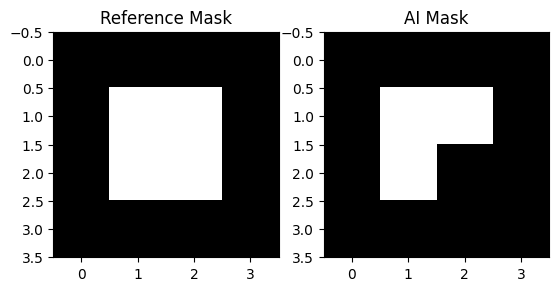

In [75]:
# Solution 6.4: Compare Reference Mask vs. AI Mask side by side (plt.subplot)
import numpy as np
import matplotlib.pyplot as plt

reference_mask = np.array([
    [0, 0, 0, 0],
    [0, 1, 1, 0],
    [0, 1, 1, 0],
    [0, 0, 0, 0]
])
ai_mask = np.array([
    [0, 0, 0, 0],
    [0, 1, 1, 0],
    [0, 1, 0, 0],
    [0, 0, 0, 0]
])

plt.subplot(1, 2, 1)
plt.imshow(reference_mask, cmap="gray")
plt.title("Reference Mask")

plt.subplot(1, 2, 2)
plt.imshow(ai_mask, cmap="gray")
plt.title("AI Mask")

plt.show()

<p><font color="#177345"><b>Solution 6.5 — Build and visualize a 3-panel Segmentation Error Map</b></font> &nbsp; <font color="#0E7490"><b>Expected:</b></font> <code>Mismatched pixels: 2</code>, followed by 3 side-by-side images</p>
<p><font color="#334155"><b>Why this works:</b> Subtracting the two masks and taking the absolute value (<code>np.abs(reference_mask - ai_mask)</code>) produces <code>0</code> everywhere the two masks agree and <code>1</code> everywhere they disagree: one missed pixel at <code>[2, 2]</code> (False Negative) and one extra pixel at <code>[2, 3]</code> (False Positive). Using <code>plt.subplot(1, 3, 1)</code>, <code>(1, 3, 2)</code>, and <code>(1, 3, 3)</code> places the Reference Mask, AI Mask, and Error Map in a single 3-panel row.</font></p>

Mismatched pixels: 2


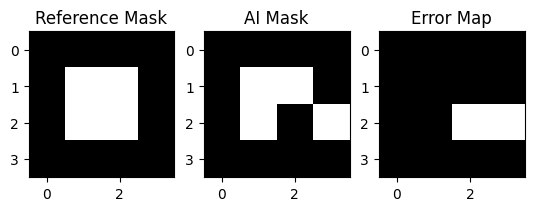

In [76]:
# Solution 6.5: Build and visualize a 3-panel Segmentation Error Map
import numpy as np
import matplotlib.pyplot as plt

reference_mask = np.array([
    [0, 0, 0, 0],
    [0, 1, 1, 0],
    [0, 1, 1, 0],
    [0, 0, 0, 0]
])
ai_mask = np.array([
    [0, 0, 0, 0],
    [0, 1, 1, 0],
    [0, 1, 0, 1],
    [0, 0, 0, 0]
])

error_map = np.abs(reference_mask - ai_mask)
print("Mismatched pixels:", error_map.sum())

plt.subplot(1, 3, 1)
plt.imshow(reference_mask, cmap="gray")
plt.title("Reference Mask")

plt.subplot(1, 3, 2)
plt.imshow(ai_mask, cmap="gray")
plt.title("AI Mask")

plt.subplot(1, 3, 3)
plt.imshow(error_map, cmap="gray")
plt.title("Error Map")

plt.show()

<hr>
<h1><font color="#1D4ED8"><b>Quick Reference — Module 3 Cheat Sheet</b></font></h1>
<p><font color="#334155">Bookmark this table! Whenever you write code to analyze CT slices, calculate organ volumes, or build figures for your research poster, you can look up the exact command here.</font></p>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:12px;">
<tr style="background:#eaf3ff">
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Lesson / Topic</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Command Pattern</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>What It Does in Medical Imaging Research</b></font></th>
</tr>
<tr>
  <td style="padding:7px"><b>1. 1D Arrays &amp; Math</b></td>
  <td style="padding:7px"><code>import numpy as np</code><br><code>arr = np.array([10, 20, 30])</code><br><code>arr * 2</code> &nbsp;|&nbsp; <code>np.abs(a - b)</code></td>
  <td style="padding:7px">Loads NumPy, creates a 1D array, and performs fast element-by-element math (such as converting voxel counts to volumes or finding absolute errors) without loops.</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>2. Inspect &amp; Summarize</b></td>
  <td style="padding:7px"><b>Facts (no <code>()</code>):</b> <code>arr.size</code>, <code>arr.shape</code>, <code>arr.dtype</code><br><b>Math (use <code>()</code>):</b> <code>arr.sum()</code>, <code>arr.mean()</code>, <code>arr.min()</code>, <code>arr.max()</code></td>
  <td style="padding:7px">Checks how many items or dimensions an array has, and computes dataset totals, averages, minimums, and maximums in one step.</td>
</tr>
<tr>
  <td style="padding:7px"><b>3. 2D Grids &amp; Cropping</b></td>
  <td style="padding:7px"><code>grid[row, col]</code><br><code>grid[r_start:r_stop, c_start:c_stop]</code><br><code>grid[0, :]</code> &nbsp;|&nbsp; <code>grid[:, 2]</code></td>
  <td style="padding:7px">Reads a single pixel at <code>(row, column)</code>, crops a rectangular Region of Interest (ROI) around an organ, or grabs a full row/column.</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>4. Masks &amp; Thresholds</b></td>
  <td style="padding:7px"><code>np.zeros((r, c), dtype=int)</code><br><code>mask = (scan &gt;= 50).astype(int)</code><br><code>overlap = ref_mask * ai_mask</code></td>
  <td style="padding:7px">Creates a blank background mask of <code>0</code>s, segments bright pixels above a threshold into <code>1</code>s, and finds where two binary masks overlap.</td>
</tr>
<tr>
  <td style="padding:7px"><b>5. Line &amp; Bar Plots</b></td>
  <td style="padding:7px"><code>import matplotlib.pyplot as plt</code><br><code>plt.plot(x, y, marker="o")</code><br><code>plt.bar(names, values)</code><br><code>plt.title()</code>, <code>plt.xlabel()</code>, <code>plt.ylabel()</code>, <code>plt.show()</code></td>
  <td style="padding:7px">Draws line trends across sequential CT slices or bar charts comparing volumes and errors across separate organs or cases.</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>6. Grayscale Images</b></td>
  <td style="padding:7px"><code>plt.imshow(grid, cmap="gray")</code><br><code>plt.colorbar()</code><br><code>plt.subplot(1, 2, 1)</code> ... <code>plt.subplot(1, 2, 2)</code></td>
  <td style="padding:7px">Turns a 2D array of numbers into a grayscale medical image, adds a brightness scale bar, and places CT slices and masks side by side.</td>
</tr>
</table>

<h3><font color="#A34F00"><b>Common Beginner Mistakes &amp; Quick Fixes</b></font></h3>
<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:12px;">
<tr style="background:#fff7ed">
  <th style="padding:8px;text-align:left"><font color="#A34F00"><b>If you see this problem...</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#A34F00"><b>Why it happened</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#177345"><b>How to fix it</b></font></th>
</tr>
<tr>
  <td style="padding:7px"><code>TypeError: 'int' object is not callable</code> on <code>arr.size()</code> or <code>arr.shape()</code></td>
  <td style="padding:7px"><code>.size</code>, <code>.shape</code>, and <code>.dtype</code> are stored facts (properties), not calculation functions.</td>
  <td style="padding:7px">Remove the parentheses: write <code>arr.size</code> and <code>arr.shape</code>.</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><code>TypeError: Cannot interpret '3' as a data type</code> on <code>np.zeros(3, 3)</code></td>
  <td style="padding:7px"><code>np.zeros()</code> expects the shape to be packaged inside its own inner parentheses as a single tuple <code>(rows, cols)</code>.</td>
  <td style="padding:7px">Use double parentheses: <code>np.zeros((3, 3), dtype=int)</code>.</td>
</tr>
<tr>
  <td style="padding:7px">You got the wrong pixel when indexing a 2D array</td>
  <td style="padding:7px">Swapped the X/Y order or forgot that Python starts counting at <code>0</code>.</td>
  <td style="padding:7px">Always go <b>Row first (top to bottom), Column second (left to right)</b>: <code>grid[row, col]</code> starting from index <code>0</code>.</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px">Your CT slice looks blue, green, and yellow instead of black and white</td>
  <td style="padding:7px">Matplotlib defaults to the colorful <code>"viridis"</code> heatmap when no colormap is specified.</td>
  <td style="padding:7px">Add <code>cmap="gray"</code> inside <code>plt.imshow(grid, cmap="gray")</code>.</td>
</tr>
</table>

<hr>
<h3><font color="#177345"><b>Congratulations on Completing Python Module 3!</b></font></h3>
<p><font color="#334155">You now have the core toolkit used in medical imaging research:</font></p>
<ul>
  <li><font color="#334155">Representing measurements and pixel grids as <b>1D and 2D NumPy arrays</b>.</font></li>
  <li><font color="#334155">Summarizing volumes and computing <b>Mean Absolute Error (MAE)</b> and <b>mask overlap</b>.</font></li>
  <li><font color="#334155">Cropping <b>Regions of Interest (ROIs)</b> and creating <b>binary segmentation masks</b> with thresholding.</font></li>
  <li><font color="#334155">Plotting research metrics and displaying side-by-side <b>CT slices, segmentation masks, and error maps</b> with Matplotlib.</font></li>
</ul>
<p><font color="#0E7490"><b>What's Next in the KSU iCARE Lab Roadmap:</b></font> <font color="#334155">In our next module, we will connect these exact NumPy and Matplotlib skills to <b>real research data tables (CSV files with Pandas) and 3D volumetric medical scans</b>!</font></p>

<hr>
<h1><font color="#1D4ED8"><b>Bonus Mini-Lab: Real Image Files, Color (RGB) Channels, Noise, and Filters</b></font></h1>
<p><font color="#0E7490"><b>Optional Guided Exploration — Run and Experiment!</b></font> <font color="#334155">In Lessons 1–6, you built 3×3 and 5×5 grids by hand so you could inspect every single pixel. In this bonus lab, you will work with larger <b>64×64 digital images</b>, learn how Python reads <b>grayscale</b> and <b>color (RGB)</b> image files from disk, simulate <b>grainy scanner noise</b>, and apply <b>smoothing</b> and <b>edge-detection filters</b> just like a real medical imaging pipeline.</font></p>

<h2><font color="#1D4ED8"><b>Bonus 1. Reading Grayscale vs. Color (RGB) Images from Disk</b></font></h2>
<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">How does Python tell the difference between a black-and-white CT slice and a full-color photograph (such as a skin lesion photo, a microscope slide, or a color-coded blood flow scan)? Look at their <b><code>.shape</code></b>:</font></p>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:8px;">
<tr style="background:#eaf3ff">
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Image Type</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>NumPy Array <code>.shape</code></b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>How Python Stores the Pixels</b></font></th>
</tr>
<tr>
  <td style="padding:7px"><b>Grayscale Image</b><br>(CT, MRI, X-ray)</td>
  <td style="padding:7px"><code>(64, 64)</code><br><b>2D Array:</b> <code>(rows, cols)</code></td>
  <td style="padding:7px">Each pixel is <b>1 number</b> representing brightness (from dark <code>0.0</code> to bright <code>1.0</code>).</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>Color (RGB) Image</b><br>(Camera photo, Pathology slide)</td>
  <td style="padding:7px"><code>(64, 64, 3)</code><br><b>3D Array:</b> <code>(rows, cols, channels)</code></td>
  <td style="padding:7px">Each pixel holds <b>3 numbers</b> stacked together: <b>Channel 0 = Red</b>, <b>Channel 1 = Green</b>, and <b>Channel 2 = Blue</b>.</td>
</tr>
</table>

<p><font color="#334155"><b>How we read image files in Python (<code>plt.imread</code>):</b></font></p>
<ul>
  <li><font color="#334155">In real projects, you load a saved image file (like <code>"scan.png"</code>) into a NumPy array using <b><code>plt.imread("scan.png")</code></b>.</font></li>
  <li><font color="#0E7490"><b>No-error Colab setup:</b></font> <font color="#334155">So you don't have to upload any outside files from your computer, the code cell below first creates a 64×64 grayscale scan and a 64×64 color RGB image, saves them to your Colab disk as <code>sample_gray.png</code> and <code>sample_color.png</code>, and then reads them back using <code>plt.imread()</code>!</font></li>
</ul>

<p><font color="#334155">Try it:</font> Run the next cell to create, save, read, and inspect both a Grayscale image and a Color (RGB) image, along with its individual Red, Green, and Blue layers.</p>

Grayscale image shape (rows, cols):           (64, 64)
Loaded Color image shape (rows, cols, RGB):   (64, 64, 3)


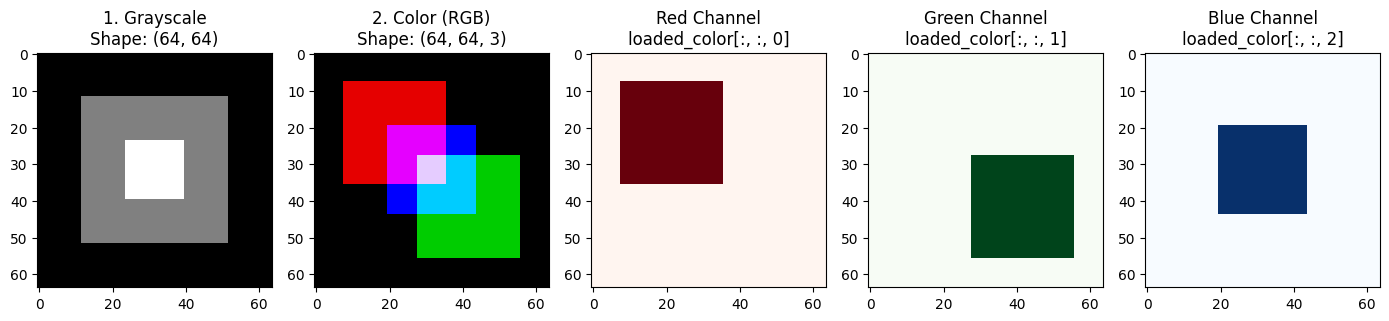

In [77]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# STEP 1: Create a 64x64 Grayscale Phantom Scan & a 64x64 Color (RGB) Image
# ---------------------------------------------------------
gray_phantom = np.zeros((64, 64), dtype=float)
gray_phantom[12:52, 12:52] = 0.5   # Medium-gray outer tissue square
gray_phantom[24:40, 24:40] = 1.0   # Bright-white inner organ square

color_phantom = np.zeros((64, 64, 3), dtype=float)
color_phantom[8:36, 8:36, 0] = 0.9    # Channel 0 (RED square in top-left)
color_phantom[28:56, 28:56, 1] = 0.8  # Channel 1 (GREEN square in bottom-right)
color_phantom[20:44, 20:44, 2] = 1.0  # Channel 2 (BLUE square in the center)

# Save the color image to Colab disk and read it back with plt.imread()
plt.imsave("sample_color.png", color_phantom)
loaded_color = plt.imread("sample_color.png")[:, :, :3]  # Keep the 3 RGB channels

print("Grayscale image shape (rows, cols):          ", gray_phantom.shape)
print("Loaded Color image shape (rows, cols, RGB):  ", loaded_color.shape)

# ---------------------------------------------------------
# STEP 2: Display Grayscale, Full Color, and the 3 RGB Channels
# ---------------------------------------------------------
plt.figure(figsize=(14, 3))

plt.subplot(1, 5, 1)
plt.imshow(gray_phantom, cmap="gray")
plt.title("1. Grayscale\nShape: (64, 64)")

plt.subplot(1, 5, 2)
plt.imshow(loaded_color)  # No cmap="gray" needed for 3-channel RGB images!
plt.title("2. Color (RGB)\nShape: (64, 64, 3)")

plt.subplot(1, 5, 3)
plt.imshow(loaded_color[:, :, 0], cmap="Reds")
plt.title("Red Channel\nloaded_color[:, :, 0]")

plt.subplot(1, 5, 4)
plt.imshow(loaded_color[:, :, 1], cmap="Greens")
plt.title("Green Channel\nloaded_color[:, :, 1]")

plt.subplot(1, 5, 5)
plt.imshow(loaded_color[:, :, 2], cmap="Blues")
plt.title("Blue Channel\nloaded_color[:, :, 2]")

plt.tight_layout()
plt.show()

<hr>
<h1><font color="#1D4ED8"><b>Bonus Mini-Lab: Color vs. Grayscale Images, Scanner Noise, and Image Filters (Lena Image)</b></font></h1>
<p><font color="#0E7490"><b>Optional Guided Exploration — Run and Experiment!</b></font> <font color="#334155">In Lessons 1–6, you worked with tiny 3×3 and 5×5 grids so you could see every number by hand. Now let's step up to the classic <b>512×512 Lena test image</b> used across computer vision and image processing courses worldwide. You will see how Python loads a real <b>Color (RGB)</b> image file, splits it into Red, Green, and Blue channels, converts it to <b>Grayscale</b>, adds simulated <b>noise</b>, and applies <b>smoothing and edge-detection filters</b>.</font></p>

<h2><font color="#1D4ED8"><b>Bonus 1. Reading a Color (RGB) Image and Converting It to Grayscale</b></font></h2>
<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">When Python reads a grayscale CT slice, each pixel is just <b>1 brightness number</b>, giving a 2D shape of <code>(rows, columns)</code>. When Python reads a <b>color photograph</b>, each pixel is a mix of <b>3 primary light colors—Red, Green, and Blue (RGB)</b>—giving a 3D shape of <code>(rows, columns, 3)</code>:</font></p>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:8px;">
<tr style="background:#eaf3ff">
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Image Format</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>NumPy <code>.shape</code></b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>How to Access the Pixels in NumPy</b></font></th>
</tr>
<tr>
  <td style="padding:7px"><b>Color (RGB) Lena</b></td>
  <td style="padding:7px"><code>(512, 512, 3)</code></td>
  <td style="padding:7px">
    • <code>lena_color[:, :, 0]</code> → <b>Red</b> channel (512×512 grid)<br>
    • <code>lena_color[:, :, 1]</code> → <b>Green</b> channel (512×512 grid)<br>
    • <code>lena_color[:, :, 2]</code> → <b>Blue</b> channel (512×512 grid)
  </td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>Grayscale Lena</b></td>
  <td style="padding:7px"><code>(512, 512)</code></td>
  <td style="padding:7px">Combines the Red, Green, and Blue channels into a single 512×512 brightness grid using the human-eye luminance formula:<br>
  <code>lena_gray = 0.2989 * R + 0.5870 * G + 0.1140 * B</code></td>
</tr>
</table>

<p><font color="#A34F00"><b>Why don't we weight Red, Green, and Blue equally when converting to Grayscale?</b></font> <font color="#334155">Human eyes are most sensitive to <b>green</b> light (58.7%), medium-sensitive to <b>red</b> light (29.9%), and least sensitive to <b>blue</b> light (11.4%). Using this weighted sum makes the grayscale image match the natural brightness your eyes perceive! Also notice that dividing an 8-bit image (<code>0</code> to <code>255</code>) by <code>255.0</code> scales all pixel intensities cleanly between <code>0.0</code> (black) and <code>1.0</code> (white).</font></p>

<p><font color="#334155">Try it:</font> Run the next cell to download <code>lena.jpg</code> into Colab, read it with <code>plt.imread()</code>, inspect its Red/Green/Blue channels, and convert it to grayscale.</p>

Color Lena shape (rows, cols, channels): (512, 512, 3) | min/max: 0.0 to 1.0
Gray  Lena shape (rows, cols):           (512, 512) | min/max: 0.08 to 0.96


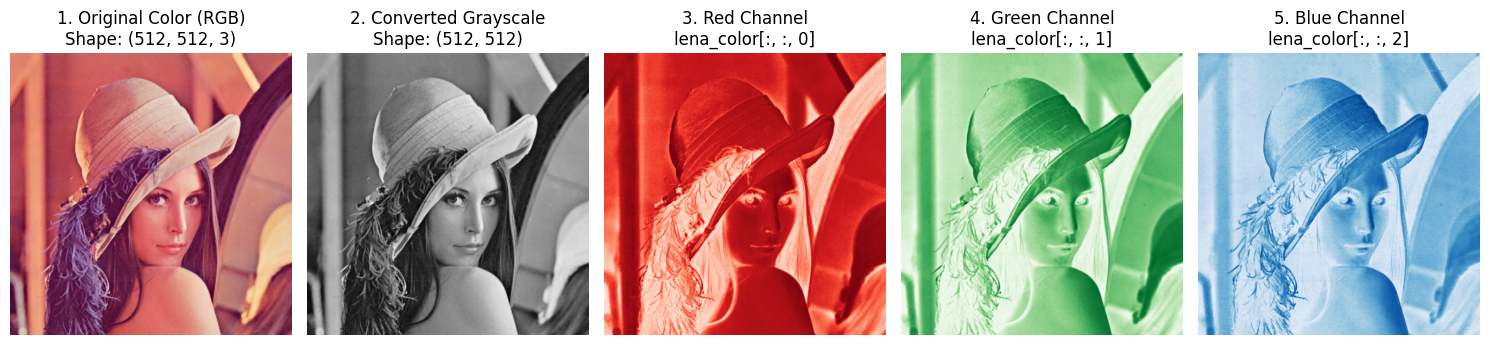

In [78]:
import urllib.request
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# STEP 1: Download the standard 512x512 Color Lena image into Colab
# ---------------------------------------------------------
url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg"
urllib.request.urlretrieve(url, "lena_color.jpg")

# Read the image file from disk (values are 0 to 255 integers)
raw_lena = plt.imread("lena_color.jpg")

# Scale pixel values to decimal numbers between 0.0 (dark) and 1.0 (bright)
lena_color = raw_lena / 255.0

# ---------------------------------------------------------
# STEP 2: Extract R, G, B channels & convert Color -> Grayscale
# ---------------------------------------------------------
R = lena_color[:, :, 0]  # Channel 0: Red
G = lena_color[:, :, 1]  # Channel 1: Green
B = lena_color[:, :, 2]  # Channel 2: Blue

# Standard luminance formula to convert RGB color to 2D grayscale
lena_gray = 0.2989 * R + 0.5870 * G + 0.1140 * B

print("Color Lena shape (rows, cols, channels):", lena_color.shape, "| min/max:", round(lena_color.min(), 2), "to", round(lena_color.max(), 2))
print("Gray  Lena shape (rows, cols):          ", lena_gray.shape,  "| min/max:", round(lena_gray.min(), 2),  "to", round(lena_gray.max(), 2))

# ---------------------------------------------------------
# STEP 3: Visualize Color, Grayscale, and the 3 RGB Channels
# ---------------------------------------------------------
plt.figure(figsize=(15, 3.5))

plt.subplot(1, 5, 1)
plt.imshow(lena_color)
plt.title("1. Original Color (RGB)\nShape: (512, 512, 3)")
plt.axis("off")

plt.subplot(1, 5, 2)
plt.imshow(lena_gray, cmap="gray")
plt.title("2. Converted Grayscale\nShape: (512, 512)")
plt.axis("off")

plt.subplot(1, 5, 3)
plt.imshow(R, cmap="Reds")
plt.title("3. Red Channel\nlena_color[:, :, 0]")
plt.axis("off")

plt.subplot(1, 5, 4)
plt.imshow(G, cmap="Greens")
plt.title("4. Green Channel\nlena_color[:, :, 1]")
plt.axis("off")

plt.subplot(1, 5, 5)
plt.imshow(B, cmap="Blues")
plt.title("5. Blue Channel\nlena_color[:, :, 2]")
plt.axis("off")

plt.tight_layout()
plt.show()

<hr>
<h2><font color="#1D4ED8"><b>Bonus 2. Adding Simulated Noise to Grayscale and Color Images</b></font></h2>
<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">Whether you are working with a camera photograph or a low-dose CT / MRI scan, real hardware sensors never capture a perfectly clean grid of numbers. Random electronic interference creates <b>image noise</b>. Because an image is just a NumPy array, we can simulate two classic types of real-world noise using NumPy math:</font></p>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:8px;">
<tr style="background:#eaf3ff">
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Noise Type</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>What It Looks Like</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>How NumPy Creates It</b></font></th>
</tr>
<tr>
  <td style="padding:7px"><b>1. Gaussian Noise</b><br>(Electronic Grain)</td>
  <td style="padding:7px">Fine static across every pixel (like a low-light photo or a low-radiation CT scan).</td>
  <td style="padding:7px"><code>np.random.normal(0, 0.12, image.shape)</code> generates random positive and negative nudges centered at <code>0</code> and adds them to the image.</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>2. Salt &amp; Pepper Noise</b><br>(Impulse / Dead Pixels)</td>
  <td style="padding:7px">Random bright white specks (<b>"salt" = <code>1.0</code></b>) and dark black specks (<b>"pepper" = <code>0.0</code></b>) scattered across the image.</td>
  <td style="padding:7px">Randomly selects a small percentage of pixels (e.g., 4% salt and 4% pepper) and overwrites them with <code>1.0</code> or <code>0.0</code>.</td>
</tr>
</table>

<p><font color="#A34F00"><b>Why do we use <code>np.clip(noisy_img, 0.0, 1.0)</code> after adding noise?</b></font> <font color="#334155">If a bright pixel is already at <code>0.95</code> and random noise adds <code>+0.15</code>, the new value becomes <code>1.10</code> (which is above the maximum legal brightness of <code>1.0</code>!). Similarly, a dark pixel could drop below <code>0.0</code>. Calling <code>np.clip(array, 0.0, 1.0)</code> trims any number below <code>0.0</code> back to <code>0.0</code> and any number above <code>1.0</code> back to <code>1.0</code>.</font></p>

<p><font color="#334155">Try it:</font> Run the next cell to add both Gaussian noise and Salt-and-Pepper noise to the <b>Grayscale</b> (top row) and <b>Color</b> (bottom row) Lena images.</p>

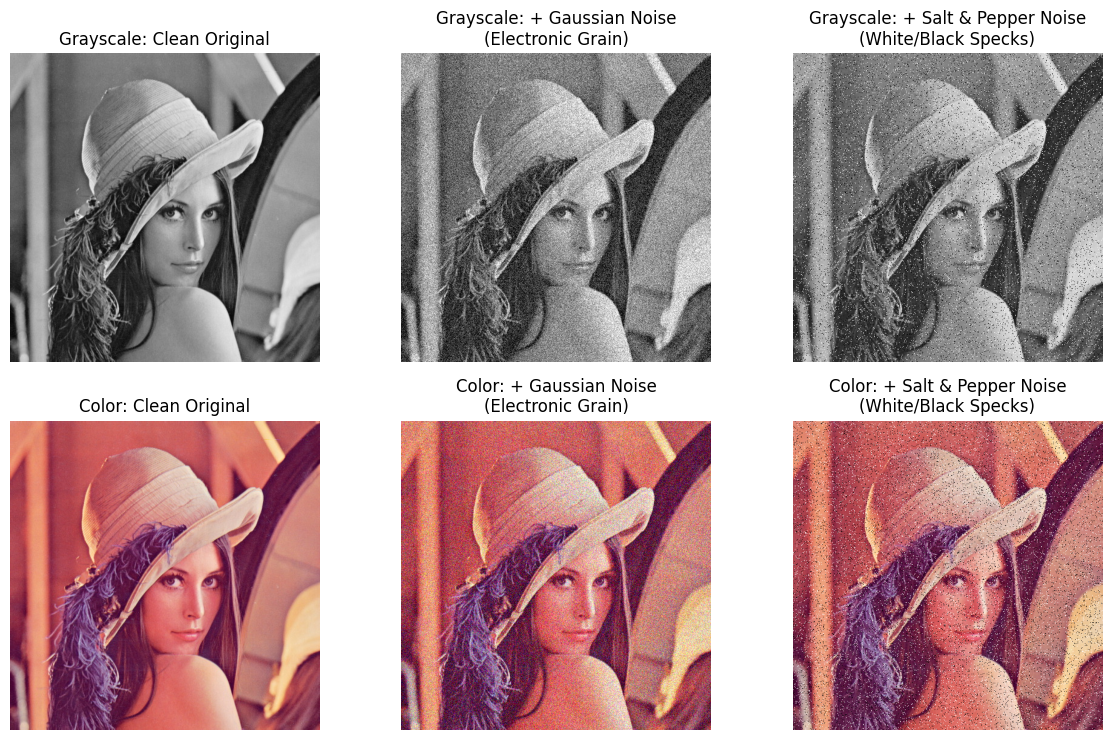

In [79]:
import numpy as np
import matplotlib.pyplot as plt

# Fix the random seed so everyone gets the exact same random noise pattern
np.random.seed(42)

# ---------------------------------------------------------
# STEP 1: Add Gaussian & Salt-and-Pepper Noise to GRAYSCALE Lena
# ---------------------------------------------------------
# 1A. Gaussian noise (electronic grain with standard deviation = 0.12)
gray_gaussian_noise = np.random.normal(0.0, 0.12, lena_gray.shape)
lena_gray_gauss = np.clip(lena_gray + gray_gaussian_noise, 0.0, 1.0)

# 1B. Salt-and-Pepper noise (4% white salt pixels, 4% black pepper pixels)
lena_gray_sp = lena_gray.copy()
rand_grid = np.random.rand(*lena_gray.shape)
lena_gray_sp[rand_grid < 0.04] = 1.0   # Salt (bright white specks)
lena_gray_sp[rand_grid > 0.96] = 0.0   # Pepper (dark black specks)

# ---------------------------------------------------------
# STEP 2: Add Gaussian & Salt-and-Pepper Noise to COLOR Lena
# ---------------------------------------------------------
# 2A. Color Gaussian noise across all (512, 512, 3) channels
color_gaussian_noise = np.random.normal(0.0, 0.12, lena_color.shape)
lena_color_gauss = np.clip(lena_color + color_gaussian_noise, 0.0, 1.0)

# 2B. Color Salt-and-Pepper noise
lena_color_sp = lena_color.copy()
rand_grid_color = np.random.rand(*lena_gray.shape)
lena_color_sp[rand_grid_color < 0.04] = 1.0  # White salt across R, G, B
lena_color_sp[rand_grid_color > 0.96] = 0.0  # Black pepper across R, G, B

# ---------------------------------------------------------
# STEP 3: Compare Clean vs. Noisy Images (Top: Grayscale, Bottom: Color)
# ---------------------------------------------------------
plt.figure(figsize=(12, 7.5))

# Top Row: Grayscale
plt.subplot(2, 3, 1)
plt.imshow(lena_gray, cmap="gray")
plt.title("Grayscale: Clean Original")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(lena_gray_gauss, cmap="gray")
plt.title("Grayscale: + Gaussian Noise\n(Electronic Grain)")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(lena_gray_sp, cmap="gray")
plt.title("Grayscale: + Salt & Pepper Noise\n(White/Black Specks)")
plt.axis("off")

# Bottom Row: Color (RGB)
plt.subplot(2, 3, 4)
plt.imshow(lena_color)
plt.title("Color: Clean Original")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(lena_color_gauss)
plt.title("Color: + Gaussian Noise\n(Electronic Grain)")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(lena_color_sp)
plt.title("Color: + Salt & Pepper Noise\n(White/Black Specks)")
plt.axis("off")

plt.tight_layout()
plt.show()

<hr>
<h2><font color="#1D4ED8"><b>Bonus 3. Applying Filters to Grayscale Images (Denoising, Edges, and Sharpening)</b></font></h2>
<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">How does an image filter clean up noise or find the outline of an organ or face? It slides a small 3×3 or 5×5 window (called a <b>kernel</b>) across every pixel in the 2D array and compares that pixel with its immediate neighbors. Using Python's built-in scientific image toolkit <b><code>scipy.ndimage</code></b>, let's test the four most important filters in image analysis:</font></p>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:8px;">
<tr style="background:#eaf3ff">
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Filter Name</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Command (<code>scipy.ndimage</code>)</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>What It Does &amp; When to Use It</b></font></th>
</tr>
<tr>
  <td style="padding:7px"><b>1. Gaussian Filter</b><br>(Smoothing / Blur)</td>
  <td style="padding:7px"><code>ndimage.gaussian_filter(img, sigma=2)</code></td>
  <td style="padding:7px">Averages each pixel with its neighbors. Higher <code>sigma</code> = stronger blur. Great for calming down grainy <b>Gaussian noise</b>.</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>2. Median Filter</b><br>(Speckle Remover)</td>
  <td style="padding:7px"><code>ndimage.median_filter(img, size=3)</code></td>
  <td style="padding:7px">Replaces each pixel with the <b>middle (median) value</b> inside a 3×3 box. Completely erases <b>Salt &amp; Pepper specks</b> without blurring sharp edges!</td>
</tr>
<tr>
  <td style="padding:7px"><b>3. Sobel Edge Filter</b><br>(Boundary Detector)</td>
  <td style="padding:7px"><code>gx = ndimage.sobel(img, axis=1)</code><br><code>gy = ndimage.sobel(img, axis=0)</code><br><code>edges = np.hypot(gx, gy)</code></td>
  <td style="padding:7px">Measures how sharply brightness changes left-to-right (<code>gx</code>) and top-to-bottom (<code>gy</code>). Smooth areas become black (<code>0</code>), while <b>boundaries light up bright white</b>!</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>4. Unsharp Mask</b><br>(Edge Sharpening)</td>
  <td style="padding:7px"><code>sharp = img + (img - blurred)</code></td>
  <td style="padding:7px">Subtracts a blurred copy from the original image to isolate fine details, then adds those details back to make boundaries crisp.</td>
</tr>
</table>

<p><font color="#334155">Try it:</font> Run the next cell to see how <b>Gaussian smoothing</b> and <b>Median filtering</b> rescue our noisy grayscale images (Top Row), and how <b>Sobel</b>, <b>Laplacian</b>, and <b>Sharpening</b> filters highlight boundaries and fine details (Bottom Row).</p>

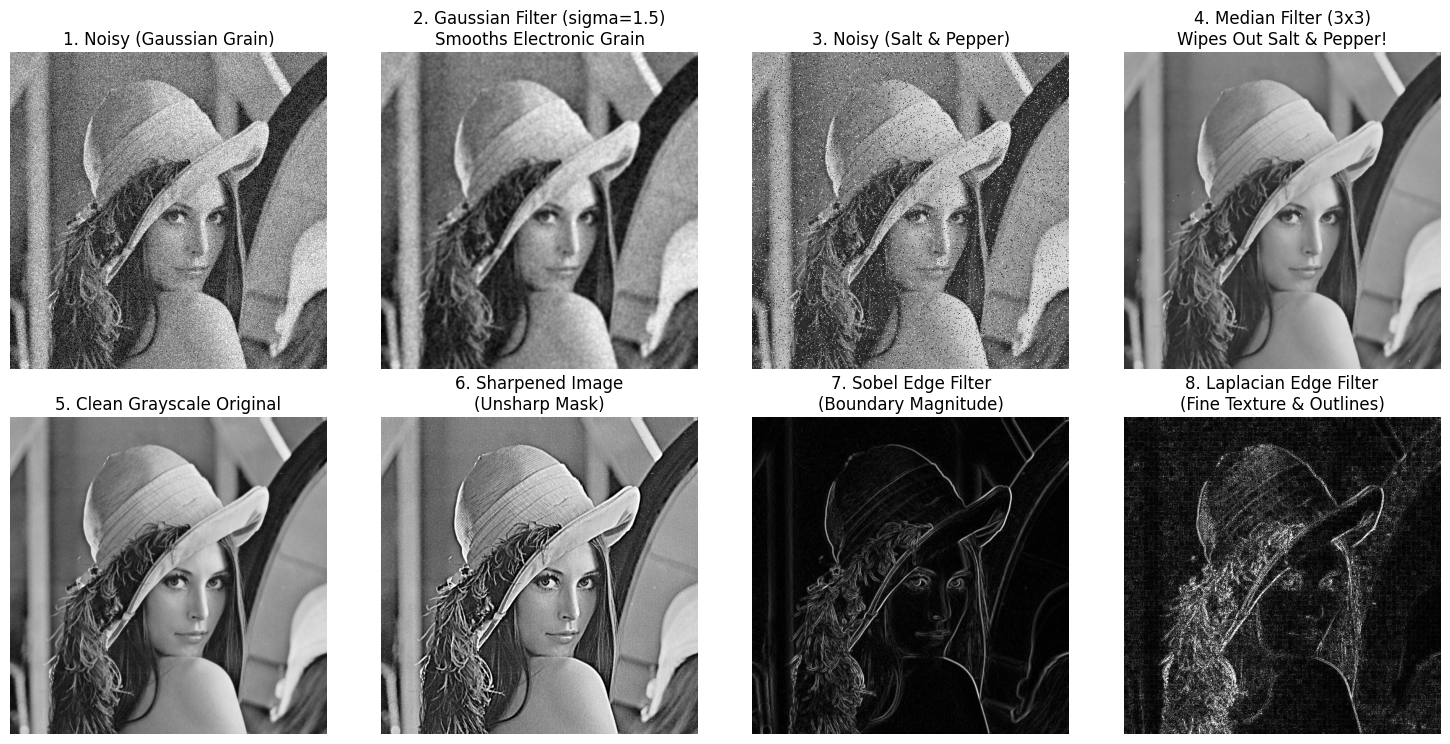

In [80]:
from scipy import ndimage
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# STEP 1: Denoising Filters on Noisy Grayscale Lena
# ---------------------------------------------------------
# Smooth the Gaussian-noisy image using a Gaussian filter (sigma = 1.5)
gray_gauss_denoised = ndimage.gaussian_filter(lena_gray_gauss, sigma=1.5)

# Clean the Salt & Pepper noisy image using a 3x3 Median filter
gray_sp_denoised = ndimage.median_filter(lena_gray_sp, size=3)

# ---------------------------------------------------------
# STEP 2: Edge Detection & Sharpening Filters on Clean Grayscale Lena
# ---------------------------------------------------------
# 2A. Sobel Edge Detection (horizontal gradient gx + vertical gradient gy)
gx = ndimage.sobel(lena_gray, axis=1)
gy = ndimage.sobel(lena_gray, axis=0)
gray_sobel_edges = np.hypot(gx, gy)
gray_sobel_edges = gray_sobel_edges / gray_sobel_edges.max()  # Scale 0.0 to 1.0

# 2B. Laplacian Filter (highlights rapid intensity changes in all directions)
gray_laplace = np.abs(ndimage.laplace(lena_gray))
gray_laplace = np.clip(gray_laplace * 3.0, 0.0, 1.0)  # Boost visibility

# 2C. Sharpening Filter (Unsharp Mask: Original + 1.5 * Fine Details)
blurred_gray = ndimage.gaussian_filter(lena_gray, sigma=2.0)
gray_sharpened = np.clip(lena_gray + 1.5 * (lena_gray - blurred_gray), 0.0, 1.0)

# ---------------------------------------------------------
# STEP 3: Display Grayscale Filtering Results (2 Rows x 4 Columns)
# ---------------------------------------------------------
plt.figure(figsize=(15, 7.5))

# Top Row: Denoising Comparison
plt.subplot(2, 4, 1)
plt.imshow(lena_gray_gauss, cmap="gray")
plt.title("1. Noisy (Gaussian Grain)")
plt.axis("off")

plt.subplot(2, 4, 2)
plt.imshow(gray_gauss_denoised, cmap="gray")
plt.title("2. Gaussian Filter (sigma=1.5)\nSmooths Electronic Grain")
plt.axis("off")

plt.subplot(2, 4, 3)
plt.imshow(lena_gray_sp, cmap="gray")
plt.title("3. Noisy (Salt & Pepper)")
plt.axis("off")

plt.subplot(2, 4, 4)
plt.imshow(gray_sp_denoised, cmap="gray")
plt.title("4. Median Filter (3x3)\nWipes Out Salt & Pepper!")
plt.axis("off")

# Bottom Row: Edge Detection & Sharpening
plt.subplot(2, 4, 5)
plt.imshow(lena_gray, cmap="gray")
plt.title("5. Clean Grayscale Original")
plt.axis("off")

plt.subplot(2, 4, 6)
plt.imshow(gray_sharpened, cmap="gray")
plt.title("6. Sharpened Image\n(Unsharp Mask)")
plt.axis("off")

plt.subplot(2, 4, 7)
plt.imshow(gray_sobel_edges, cmap="gray")
plt.title("7. Sobel Edge Filter\n(Boundary Magnitude)")
plt.axis("off")

plt.subplot(2, 4, 8)
plt.imshow(gray_laplace, cmap="gray")
plt.title("8. Laplacian Edge Filter\n(Fine Texture & Outlines)")
plt.axis("off")

plt.tight_layout()
plt.show()

<hr>
<h2><font color="#1D4ED8"><b>Bonus 4. Applying Filters to a 3D Color (RGB) Image</b></font></h2>
<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">What changes when you apply a filter to a <b>Color (RGB)</b> image of shape <code>(512, 512, 3)</code> instead of a 2D grayscale image of shape <code>(512, 512)</code>? You must tell Python to filter along the <b>Rows (Axis 0)</b> and <b>Columns (Axis 1)</b>, while keeping the <b>3 Color Channels (Axis 2) separate</b>!</font></p>

<p><font color="#A34F00"><b>Watch out for this classic 3D color filtering mistake:</b></font></p>
<ul>
  <li><font color="#A34F00"><b>Wrong way:</b></font> <font color="#334155">If you write <code>ndimage.gaussian_filter(lena_color, sigma=3)</code> with a single number, SciPy blurs across rows, columns, <b>AND across the Red, Green, and Blue channels</b>—mixing the colors together into a washed-out gray!</font></li>
  <li><font color="#177345"><b>Right way:</b></font> <font color="#334155">Pass a 3-number tuple <b><code>sigma=(3, 3, 0)</code></b>! That tells SciPy: <i>"Blur by 3 pixels vertically, 3 pixels horizontally, and <b>0</b> across the color channels."</i> Similarly, for a 3×3 median filter on a color image, pass <b><code>size=(3, 3, 1)</code></b> so each RGB channel is cleaned independently.</font></li>
</ul>

<p><font color="#0E7490"><b>How Color Edge Detection works:</b></font> <font color="#334155">If we compute the Sobel edge map separately on the Red channel, the Green channel, and the Blue channel, and stack them back into a 3-channel RGB image, we get a <b>Color Edge Map</b> where red boundaries glow red, green boundaries glow green, and white boundaries (where all 3 channels change together) glow bright white!</font></p>

<p><font color="#334155">Try it:</font> Run the next cell to compare <b>Color Gaussian Denoising</b>, <b>Color Median Filtering</b>, <b>Color Sharpening</b>, and <b>RGB Color Edge Detection</b> on the Lena image.</p>

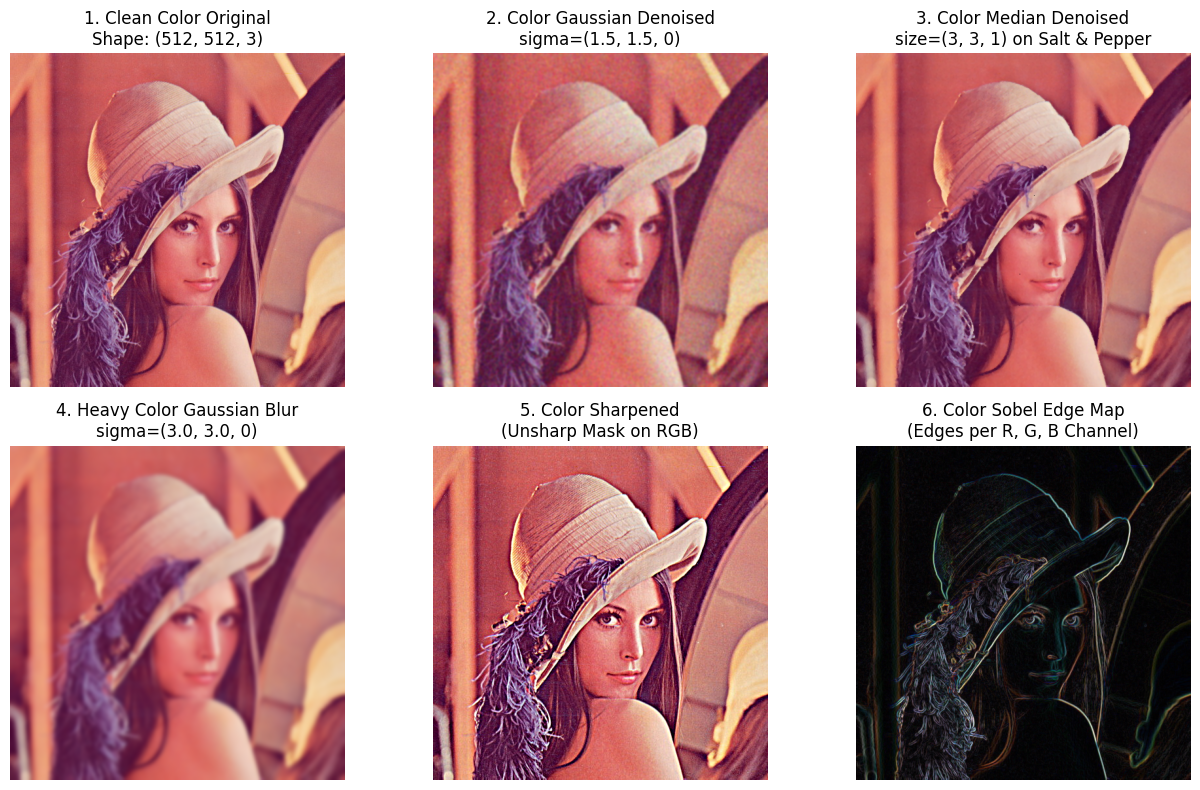

In [81]:
from scipy import ndimage
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# STEP 1: Denoise & Blur Color Lena (keeping RGB channels separate!)
# ---------------------------------------------------------
# 1A. Smooth Gaussian-noisy color image: sigma=(1.5, 1.5, 0) -> 0 blur across RGB!
color_gauss_denoised = ndimage.gaussian_filter(lena_color_gauss, sigma=(1.5, 1.5, 0))

# 1B. Clean Salt & Pepper color image: size=(3, 3, 1) -> 3x3 per color channel
color_sp_denoised = ndimage.median_filter(lena_color_sp, size=(3, 3, 1))

# 1C. Strong Gaussian Blur vs. Color Sharpening on Clean Lena
color_blurred = ndimage.gaussian_filter(lena_color, sigma=(3.0, 3.0, 0))
color_sharpened = np.clip(lena_color + 1.5 * (lena_color - color_blurred), 0.0, 1.0)

# ---------------------------------------------------------
# STEP 2: Compute a 3-Channel RGB Color Sobel Edge Map
# ---------------------------------------------------------
color_edges = np.zeros_like(lena_color)
for ch in range(3):  # Loop over Channel 0 (Red), 1 (Green), and 2 (Blue)
    gx_ch = ndimage.sobel(lena_color[:, :, ch], axis=1)
    gy_ch = ndimage.sobel(lena_color[:, :, ch], axis=0)
    mag_ch = np.hypot(gx_ch, gy_ch)
    color_edges[:, :, ch] = mag_ch / mag_ch.max()

# ---------------------------------------------------------
# STEP 3: Display Color Filtering Results (2 Rows x 3 Columns)
# ---------------------------------------------------------
plt.figure(figsize=(13, 8))

plt.subplot(2, 3, 1)
plt.imshow(lena_color)
plt.title("1. Clean Color Original\nShape: (512, 512, 3)")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(color_gauss_denoised)
plt.title("2. Color Gaussian Denoised\nsigma=(1.5, 1.5, 0)")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(color_sp_denoised)
plt.title("3. Color Median Denoised\nsize=(3, 3, 1) on Salt & Pepper")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(color_blurred)
plt.title("4. Heavy Color Gaussian Blur\nsigma=(3.0, 3.0, 0)")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(color_sharpened)
plt.title("5. Color Sharpened\n(Unsharp Mask on RGB)")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(color_edges)
plt.title("6. Color Sobel Edge Map\n(Edges per R, G, B Channel)")
plt.axis("off")

plt.tight_layout()
plt.show()